# **Methodology - *Towards a global database of animal sound amplitudes***

---
## **Context**

In order to simulate sound recordings containing two species, A and B, located at different distances from the microphone, the goal is to compute:

- **X**: the real amplitude difference between A and B (in dB)  
- **X'**: the observed amplitude difference in the simulated recording (in dB) 
- **X' – X**: the recording error  

#### **Spherical spreading**

Intensity (I, measured as the amplitude of pressure waves) at distance (radius) r is the reference intensity (I<sub>0</sub>, usually measured at 1 meter) divided by r<sup>2</sup>:
- **I(r) = I<sub>0</sub>/r<sup>2</sup>**

In decibels, pressure level (PL) at a distance r is the reference pressure level minus 20 log<sub>10</sub>(r):
- **PL(r) = PL<sub>0</sub> - 20 log<sub>10</sub>(r)**

If r = 1 (reference), the attenuation is 0. Sound amplitude drops ~ 6 dB every doubling of distance.

Example:
- r = 1  :  db = 80.00 
- r = 2  : db = 73.98 : dif = 6.02
- r = 4  : db = 67.96 : dif = 6.02
- r = 8  : db = 61.94 : dif = 6.02
- r = 16 : db = 55.92 : dif = 6.02


\
So, for species A and B, the recorded amplitude (in dB) is the amplitude at the reference distance minus the attenuation at the recorded distance:

PL<sub>a</sub>' = PL<sub>a</sub> - 20 log<sub>10</sub>(r<sub>a</sub>)

PL<sub>b</sub>' = PL<sub>b</sub> - 20 log<sub>10</sub>(r<sub>b</sub>)

#### **Observed amplitude difference**

X' = PL<sub>b</sub>' - PL<sub>a</sub>'


#### **Real amplitude difference**


X = PL<sub>b</sub> - PL<sub>a</sub>


#### **Error produced by the recording**

X' - X = PL<sub>b</sub>' - PL<sub>a</sub>' - (PL<sub>b</sub> - PL<sub>a</sub>)\
X' - X = PL<sub>b</sub>' - PL<sub>a</sub>' - PL<sub>b</sub> + PL<sub>a</sub>\
X' - X = (PL<sub>b</sub> - 20 log<sub>10</sub>(r<sub>b</sub>)
) - (PL<sub>a</sub> - 20 log<sub>10</sub>(r<sub>a</sub>)) - PL<sub>b</sub> + PL<sub>a</sub>\
X' - X = PL<sub>b</sub> - 20 log<sub>10</sub>(r<sub>b</sub>) - PL<sub>a</sub> + 20 log<sub>10</sub>(r<sub>a</sub>) - PL<sub>b</sub> + PL<sub>a</sub>\
X' - X = 20 log<sub>10</sub>(r<sub>a</sub>) - 20 log<sub>10</sub>(r<sub>b</sub>)\
**X' - X = 20 log<sub>10</sub>(r<sub>a</sub>/r<sub>b</sub>)**

- The error depends only on the distance ratio (r<sub>a</sub>/r<sub>b</sub>)

---
## **Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import AutoMinorLocator
from itertools import combinations

---
## **Formulas**

##### Mean
###### Corresponds with `mean_f()`

$$
\frac{1}{n} \sum_{i=1}^{n} x_i
$$

##### Variance
###### Corresponds with `variance_f()`

$$
\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2
$$


##### Standard Deviation
###### Corresponds with `std_dev_f()`

$$
\sqrt{\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2}
$$


##### Skewness
###### Corresponds with `skewness_f()`

$$
\frac
{\frac{1}{n}\sum_{i=1}^{n}
\left(x_i - \bar{x}
\right)^3}
{s^3}
$$


##### Kurtosis
###### Corresponds with `kurtosis_f()`

$$
\frac
{\frac{1}{n}\sum_{i=1}^{n}
\left(x_i - \bar{x}
\right)^4}
{s^4}
$$


In [3]:
### FORMULA DEFINITIONS

rng = np.random.default_rng(seed=123)
data = rng.normal(loc=0, scale=30, size=1000000)

# MEAN
def mean_f(data):
	return sum(data) / len(data)

# MEDIAN
def median_f(data):
	sorted_data = sorted(data)
	n = len(sorted_data)
	mid = n // 2
	if n % 2 == 0:
		return (sorted_data[mid - 1] + sorted_data[mid]) / 2
	else:
		return sorted_data[mid]

# VARIANCE
def variance_f(data):    
	mean = mean_f(data)
	return sum((x - mean) ** 2 for x in data) / len(data)

# STANDARD DEVIATION
def std_dev_f(data):
	return variance_f(data) ** 0.5

# STANDARD ERROR
def std_error_f(data):
	return std_dev_f(data) / (len(data) ** 0.5)


# SKEWNESS
def skewness_f(data):
	mean = mean_f(data)
	std_dev = std_dev_f(data)
	n = len(data)
	return (sum((x - mean) ** 3 for x in data) / n) / (std_dev ** 3)

# KURTOSIS
def kurtosis_f(data):
	mean = mean_f(data)
	std_dev = std_dev_f(data)
	n = len(data)
	return (sum((x - mean) ** 4 for x in data) / n) / (std_dev ** 4)

---
## **Simulation scenarios**

#### Theoretical Simulation Framework

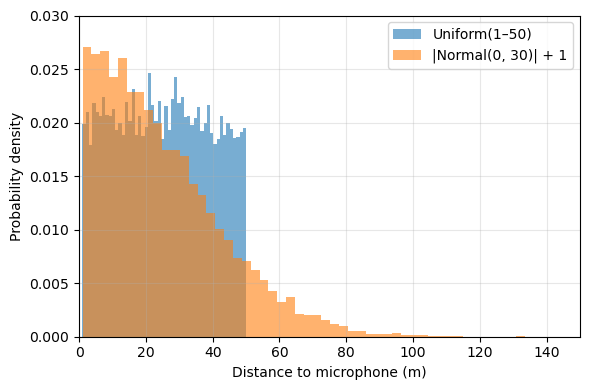

In [4]:
def plot_distance_distributions(N, sigma, seed):
	rng = np.random.default_rng(seed)

	# Uniform
	uni = rng.uniform(1, 50, size=N)

	# |Normal(0, sigma)| + 1 (decay with distance)
	dwd = np.abs(rng.normal(0, sigma, size=N)) + 1

	plt.figure(figsize=(6,4))
	plt.hist(uni, bins=50, density=True, alpha=0.6, label="Uniform(1–50)")
	plt.hist(dwd, bins=50, density=True, alpha=0.6, label=f"|Normal(0, {sigma})| + 1")

	plt.xlabel("Distance to microphone (m)")
	plt.ylabel("Probability density")
	# plt.title(f"Simulated distance distributions (N = {N})")
	plt.xlim(0, 150)
	plt.ylim(0, 0.03)
	plt.legend()
	plt.grid(alpha=0.3)
	plt.tight_layout()
	plt.show()

plot_distance_distributions(N=10000, sigma=30, seed=123)

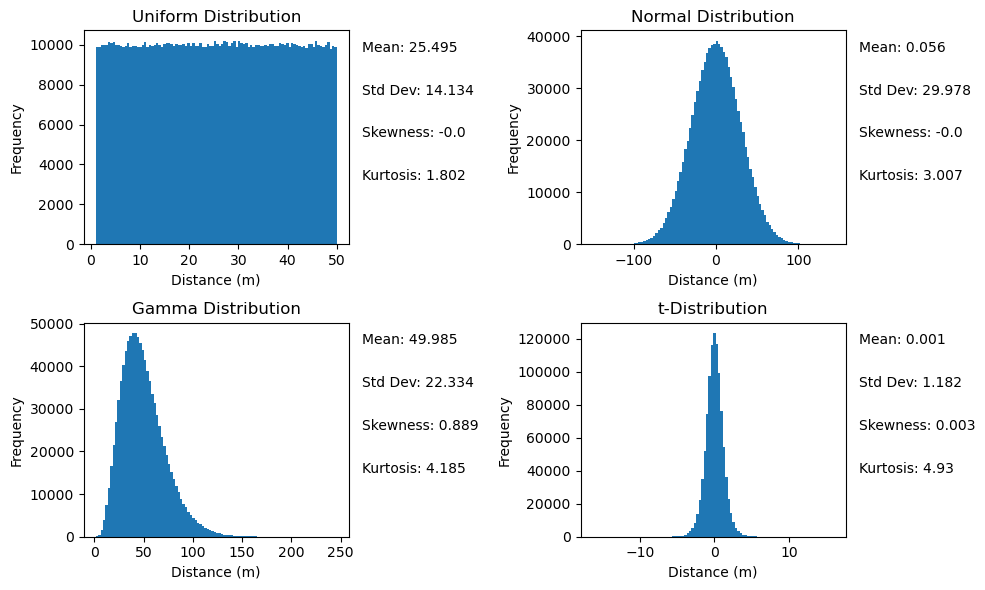

In [5]:
# Variables
N = 1000000
rng = np.random.default_rng(seed=123)
mean = 0
sd = 30

samples_uniform = rng.uniform(1, 50, size=N)
samples_normal = rng.normal(mean, sd, size=N)
samples_gamma = rng.gamma(shape=5, scale=10, size=N)
samples_t = rng.standard_t(df=7, size=N)


fig, axs = plt.subplots(2, 2, figsize=(10,6))

axs[0,0].hist(samples_uniform, bins=100)
axs[0,0].set_xlabel("Distance (m)")
axs[0,0].set_ylabel("Frequency")
axs[0,0].set_title("Uniform Distribution")
axs[0,0].text(1.05, 0.9, f"Mean: {round(mean_f(samples_uniform), 3)}", transform=axs[0,0].transAxes)
axs[0,0].text(1.05, 0.7, f"Std Dev: {round(std_dev_f(samples_uniform), 3)}", transform=axs[0,0].transAxes)
axs[0,0].text(1.05, 0.5, f"Skewness: {round(skewness_f(samples_uniform), 3)}", transform=axs[0,0].transAxes)
axs[0,0].text(1.05, 0.3, f"Kurtosis: {round(kurtosis_f(samples_uniform), 3)}", transform=axs[0,0].transAxes)

axs[0,1].hist(samples_normal, bins=100)
axs[0,1].set_xlabel("Distance (m)")
axs[0,1].set_ylabel("Frequency")
axs[0,1].set_title("Normal Distribution")
axs[0,1].text(1.05, 0.9, f"Mean: {round(mean_f(samples_normal), 3)}", transform=axs[0,1].transAxes)
axs[0,1].text(1.05, 0.7, f"Std Dev: {round(std_dev_f(samples_normal), 3)}", transform=axs[0,1].transAxes)
axs[0,1].text(1.05, 0.5, f"Skewness: {round(skewness_f(samples_normal), 3)}", transform=axs[0,1].transAxes)
axs[0,1].text(1.05, 0.3, f"Kurtosis: {round(kurtosis_f(samples_normal), 3)}", transform=axs[0,1].transAxes)

axs[1,0].hist(samples_gamma, bins=100)
axs[1,0].set_xlabel("Distance (m)")
axs[1,0].set_ylabel("Frequency")
axs[1,0].set_title("Gamma Distribution")
axs[1,0].text(1.05, 0.9, f"Mean: {round(mean_f(samples_gamma), 3)}", transform=axs[1,0].transAxes)
axs[1,0].text(1.05, 0.7, f"Std Dev: {round(std_dev_f(samples_gamma), 3)}", transform=axs[1,0].transAxes)
axs[1,0].text(1.05, 0.5, f"Skewness: {round(skewness_f(samples_gamma), 3)}", transform=axs[1,0].transAxes)
axs[1,0].text(1.05, 0.3, f"Kurtosis: {round(kurtosis_f(samples_gamma), 3)}", transform=axs[1,0].transAxes)

axs[1,1].hist(samples_t, bins=100)
axs[1,1].set_xlabel("Distance (m)")
axs[1,1].set_ylabel("Frequency")
axs[1,1].set_title("t-Distribution")
axs[1,1].text(1.05, 0.9, f"Mean: {round(mean_f(samples_t), 3)}", transform=axs[1,1].transAxes)
axs[1,1].text(1.05, 0.7, f"Std Dev: {round(std_dev_f(samples_t), 3)}", transform=axs[1,1].transAxes)
axs[1,1].text(1.05, 0.5, f"Skewness: {round(skewness_f(samples_t), 3)}", transform=axs[1,1].transAxes)
axs[1,1].text(1.05, 0.3, f"Kurtosis: {round(kurtosis_f(samples_t), 3)}", transform=axs[1,1].transAxes)

plt.tight_layout()
plt.show()


### **Scenario 1)**

The first scenario considers only two species A and B, with known sound amplitudes, which are recorded together repeatedly with their orientation and distances to the microphone varying randomly. We simulate multiple recordings containing both species A and B, compute the distance-dependent spherical sound attenuation for A and for B in each simulated recording, and compute the difference in relative sound amplitude “A-B”.

In this simple scenario, after many simulations the mean distance of A and B to the microphone will be similar, without bias favouring species A or B. Thus, we can evaluate the confidence in their relative amplitude difference simply using the standard error of A-B differences across the multiple recordings.

1st stage:
- A single set of simulations is performed

2nd stage:
- Several sets of simulations are performed so we can sample the convergence entry point 

#### Base

UNIFORM:
Mean of X' - X: -0.1206 dB
Standard deviation of X' - X: 10.0314 dB
Skewness of X' - X: -0.0534 dB
Kurtosis of X' - X: 3.5969 dB



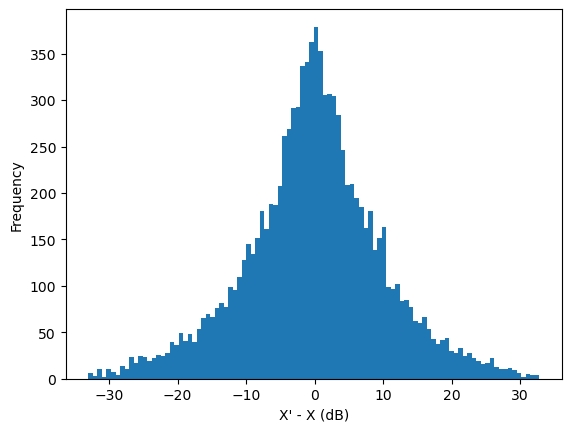

|Normal(0, 30)| + 1 (capped at 50):
Mean of X' - X: -0.0857 dB
Standard deviation of X' - X: 11.3320 dB
Skewness of X' - X: -0.0079 dB
Kurtosis of X' - X: 3.0784 dB



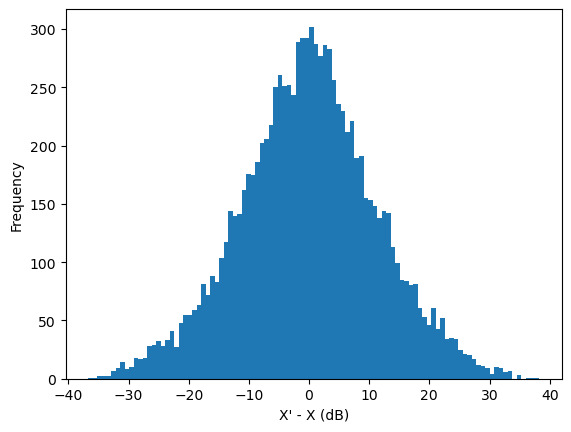

In [6]:
# Variables
N = 10000
rng = np.random.default_rng(seed=123)
min_dist_U = 1
max_dist_U = 50
sd_hn = 30 

# Samples: uniform distribution
rA_U = rng.uniform(min_dist_U, max_dist_U, size=N)
rB_U = rng.uniform(min_dist_U, max_dist_U, size=N)

# Samples: dwd distribution,
rA_DWD = np.abs(rng.normal(loc=0, scale=sd_hn, size=N)) + 1
rB_DWD = np.abs(rng.normal(loc=0, scale=sd_hn, size=N)) + 1

# Calculate X' - X (uniform)
dif_X_U = 20 * np.log10(rA_U / rB_U)

# Calculate X' - X (dwd)
dif_X_DWD = 20 * np.log10(rA_DWD / rB_DWD)


#################################
#   Summary + histograms
#################################

# UNIFORM summary
print(f"UNIFORM:")
print(f"Mean of X' - X: {mean_f(dif_X_U):.4f} dB")
print(f"Standard deviation of X' - X: {std_dev_f(dif_X_U):.4f} dB")
print(f"Skewness of X' - X: {skewness_f(dif_X_U):.4f} dB")
print(f"Kurtosis of X' - X: {kurtosis_f(dif_X_U):.4f} dB\n")

plt.hist(dif_X_U, bins=100)
plt.xlabel("X' - X (dB)")
plt.ylabel("Frequency")
# plt.title("Scenario 1: Uniform distribution of X' - X")
plt.show()


# NORMAL
print(f"|Normal(0, {sd_hn})| + 1 (capped at 50):")
print(f"Mean of X' - X: {mean_f(dif_X_DWD):.4f} dB")
print(f"Standard deviation of X' - X: {std_dev_f(dif_X_DWD):.4f} dB")
print(f"Skewness of X' - X: {skewness_f(dif_X_DWD):.4f} dB")
print(f"Kurtosis of X' - X: {kurtosis_f(dif_X_DWD):.4f} dB\n")

plt.hist(dif_X_DWD, bins=100)
plt.xlabel("X' - X (dB)")
plt.ylabel("Frequency")
# plt.title("Scenario 1: |Normal(0, sd)| + 1 distribution of X' - X")
plt.show()

#### 1st stage

Function to simulate one single run

In [7]:
def run_simulation_path(
	rng,
	distr,                 
	max_steps=100,
	min_dist=1,            
	max_dist=50,          
	sd=None               
):
	dif_X = np.empty(max_steps, dtype=float)

	for i in range(max_steps):

		if distr == "uniform":
			rA = rng.uniform(min_dist, max_dist)
			rB = rng.uniform(min_dist, max_dist)

		elif distr == "dwd":
			if sd is None:
				raise ValueError("For distr='dwd', you must provide sd.")
			rA = abs(rng.normal(0, sd)) + 1
			rB = abs(rng.normal(0, sd)) + 1

		else:
			raise ValueError("distr must be one of: 'uniform', 'dwd'.")

		dif_X[i] = 20 * np.log10(rA / rB)

	running_mean = np.cumsum(dif_X) / np.arange(1, max_steps + 1)
	return dif_X, running_mean


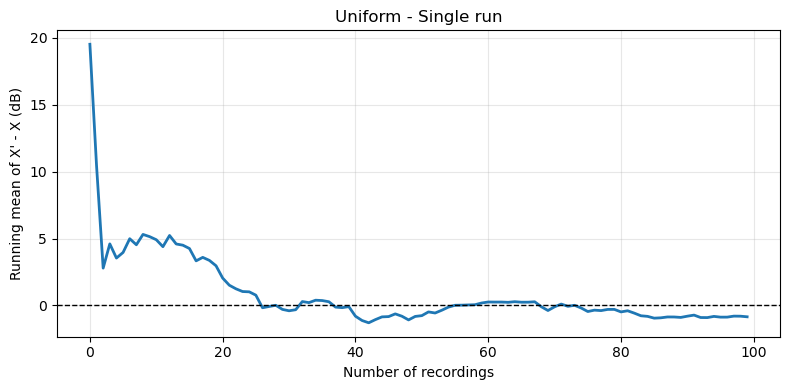

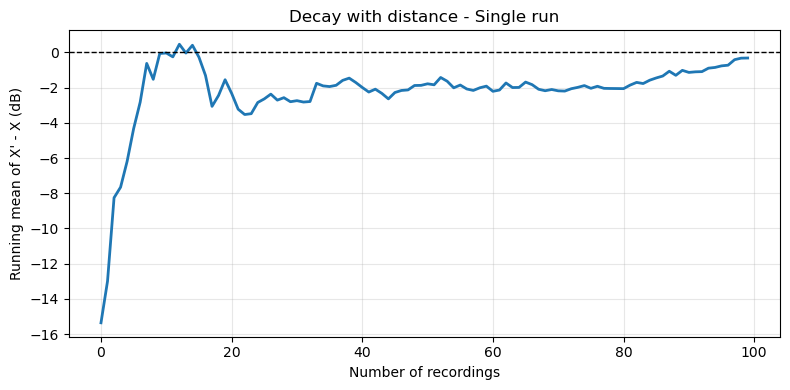

In [8]:
# Variables
rng = np.random.default_rng(seed=123)
max_steps=100
min_dist=1            
max_dist=50          
sd=30  

# Single run UNIFORM

dif_X, running_mean = run_simulation_path(
	rng,
	distr="uniform", 
	max_steps=max_steps,
	min_dist=min_dist,
	max_dist=max_dist,
	sd=sd
)

# UNIFORM Plot

plt.figure(figsize=(8, 4))
plt.plot(running_mean, color="tab:blue", linewidth=2)
plt.axhline(0, linestyle="--", linewidth=1, color="black") # y = 0 line
plt.xlabel("Number of recordings")
plt.ylabel("Running mean of X' - X (dB)")
plt.title("Uniform - Single run")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Single run DWD

dif_X, running_mean = run_simulation_path(
	rng,
	distr="dwd", 
	max_steps=max_steps,
	min_dist=min_dist,
	max_dist=max_dist,
	sd=sd
)

# NORMAL Plot

plt.figure(figsize=(8, 4))
plt.plot(running_mean, color="tab:blue", linewidth=2)
plt.axhline(0, linestyle="--", linewidth=1, color="black") # y = 0 line
plt.xlabel("Number of recordings")
plt.ylabel("Running mean of X' - X (dB)")
plt.title("Decay with distance - Single run")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 2nd stage

Function to simulate and plot replicates and mean runs

In [9]:
def plot_running_mean_runs(
	rng,
	distr,
	R,
	max_steps,
	min_dist,
	max_dist,
	sd=None,
	xlim=None,
	ylim=None,
	title=None,
	alpha_runs=0.25,
	lw_runs=1.0,
	lw_mean=2.5,
	runs_color="tab:blue",
	mean_color="red"
):
	rms = np.empty((R, max_steps), dtype=float)

	for i in range(R):
		_, rm = run_simulation_path(
			rng,
			distr=distr,
			max_steps=max_steps,
			min_dist=min_dist,
			max_dist=max_dist,
			sd=sd
		)
		rms[i, :] = rm

	mean_rm = rms.mean(axis=0)
	sd_rm = rms.std(axis=0, ddof=1)

	fig, ax = plt.subplots(figsize=(8, 4))

	# All runs
	for i in range(R):
		ax.plot(
			rms[i, :],
			alpha=alpha_runs,
			linewidth=lw_runs,
			color=runs_color,
			zorder=1
		)
	# ± SD band
	ax.fill_between(
		np.arange(max_steps),
		mean_rm - sd_rm,
		mean_rm + sd_rm,
		color=mean_color,
		alpha=0.20,
		# label="Standard deviation",
		zorder=2
	)
	"""
	# Mean line
	ax.plot(
		mean_rm,
		color=mean_color,
		linewidth=lw_mean,
		label="Mean running mean",
		zorder=3
	)
	"""
	ax.axhline(0, linestyle="--", linewidth=1, color="black", zorder=4)

	ax.set_xlabel("Number of recordings")
	ax.set_ylabel("Running mean of Estimate Error (dB)")

	# if title is None:
	# 	title = f"{distr}: {R} running-mean trajectories (max_steps={max_steps})"
	# ax.set_title(title)

	ax.grid(alpha=0.3)
	ax.legend()

	if xlim is not None:
		ax.set_xlim(xlim)
	if ylim is not None:
		ax.set_ylim(ylim)

	plt.tight_layout()
	plt.show()

	return rms, mean_rm, sd_rm

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\714532105.py:75: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


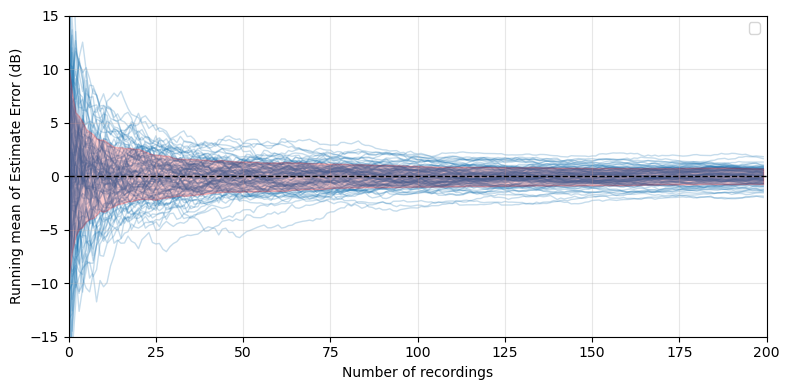

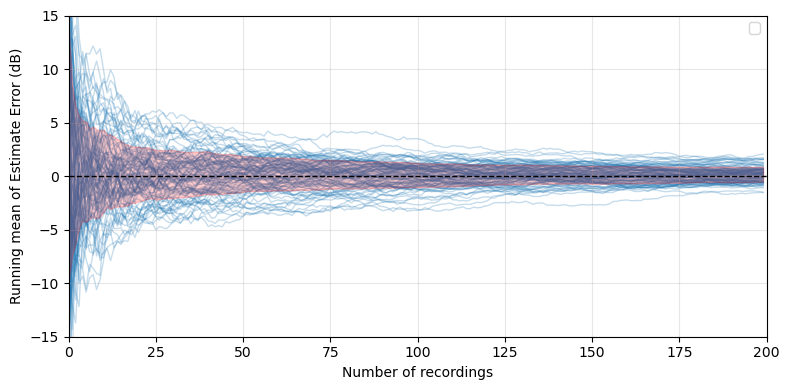

In [10]:
rng = np.random.default_rng(seed=123)
R = 100
min_dist = 1
max_dist = 50
max_steps = 200
ylim = (-15, 15)

rms, mean_rm, sd_rm = plot_running_mean_runs(
	rng,
	distr="uniform",
	R=R,
	max_steps=max_steps,
	min_dist=min_dist,
	max_dist=max_dist,
	xlim=(0, max_steps),
	ylim=ylim,
	# title="Uniform: running mean trajectories",
	runs_color="tab:blue",
	mean_color="red"
)

rng = np.random.default_rng(seed=123)

rms, mean_rm, sd_rm = plot_running_mean_runs(
	rng,
	distr="dwd",        
	R=R,
	max_steps=max_steps,
	min_dist=min_dist,
	max_dist=max_dist,
	sd=30,
	xlim=(0, max_steps),
	ylim=ylim,
	# title="Decay with distance: running mean trajectories",
	runs_color="tab:blue",
	mean_color="red"
)

### **Scenario 2)**

The second scenario again considers only two species, A and B, but we now break the assumption that their distances to the microphone are on average similar. This may happen, for example, if A tolerates disturbance more than B, or if its detection range is shorter.

In this scenario, averaging the amplitude differences A-B will be biased towards overestimating the amplitude of B (on average closer to the microphone). 

Our preliminary simulations show that here the distribution of A-B differences is no longer symmetrical: it will be asymmetrically skewed and with higher kurtosis compared to scenario 1. Our goal with simulations in this scenario 2 is to develop and test a correction factor, based on the skew and kurtosis of the A-B distribution, that removes bias in the estimation of the A-B difference, and that adjusts its standard error accordingly. This makes our method applicable even to species that differ markedly in the detection range of their sounds.

#### Pre 1st and 2nd stages

Functions for distribution sampling and for convergence sampling (1st and 2nd stages)

In [12]:
### For the distribution sampling (N runs)
# Generates a single vector for all the N runs (order irrelevant)

def uniform_vec(rng, lower=1, upper=50, size=10000):
	return rng.uniform(lower, upper, size=size)

def dwd_vec(rng, sd, size=10000):
	# r = |Normal(0, sd)| + 1 
	return np.abs(rng.normal(loc=0, scale=sd, size=size)) + 1



### For the convergence sampling (sequential runs)
# Generates a single value per step (order matters)

def uniform_1(rng, lower=1, upper=50):
	return rng.uniform(lower, upper)

def dwd_1(rng, sd):
	# r = |Normal(0, sd)| + 1 
	return np.abs(rng.normal(loc=0, scale=sd)) + 1


#### 1st stage

Running the distribution sampling

In [13]:
N = 1000000
rng = np.random.default_rng(seed=123)

min_dist = 1
max_dist = 50

k_list = [1, 0.9, 0.8, 0.7, 0.6 , 0.5, 0.4, 0.3, 0.2, 0.1]

# Parameters for A in absnormal
sd_A = 30  

distr_list = ["uniform", "dwd"]

results = {distr: {} for distr in distr_list}  # results[distr][k] = metrics dict


for distr in distr_list:

	# Draw rA once for metrics (per distribution)
	if distr == "uniform":
		rA = rng.uniform(min_dist, max_dist, size=N)

	elif distr == "dwd":
		rA = np.abs(rng.normal(loc=0, scale=sd_A, size=N)) + 1

	else:
		raise ValueError("Invalid distr.")

	for k in k_list:

		# Draw rB given k
		if distr == "uniform":
			# shrink upper bound so mean(rB) is smaller
			rB = rng.uniform(min_dist, min_dist + k * (max_dist - min_dist), size=N)

		elif distr == "dwd":
			# make B closer on average by shrinking sd
			sd_B = k * sd_A
			rB = np.abs(rng.normal(loc=0, scale=sd_B, size=N)) + 1

		# Estimate Error
		dif_X = 20 * np.log10(rA / rB)


		### Metrics

		# Mean
		mean_dif = mean_f(dif_X)

		# Standard deviation
		sd_dif = std_dev_f(dif_X)

		# Skewness
		skew =skewness_f(dif_X)

		# Kurtosis
		kurt = kurtosis_f(dif_X)

		results[distr][k] = {
			"rA_mean": rA.mean(),
			"rB_mean": rB.mean(),
			"mean": mean_dif,
			"sd": sd_dif,
			"skew": skew,
			"kurt": kurt,
			"dif_X": dif_X
		}

Visualization of the distribution of runs



==================== UNIFORM ====================

Summary metrics:

k = 1
  Mean distance A               = 25.495
  Mean distance B               = 25.513
  Mean of Estimate Error        = -0.0030 dB
  SD of Estimate Error          = 10.1234 dB
  Skewness of Estimate Error    = 0.0041
  Kurtosis of Estimate Error    = 3.5559

k = 0.9
  Mean distance A               = 25.495
  Mean distance B               = 23.052
  Mean of Estimate Error        = 0.8440 dB
  SD of Estimate Error          = 10.0740 dB
  Skewness of Estimate Error    = -0.0272
  Kurtosis of Estimate Error    = 3.5243

k = 0.8
  Mean distance A               = 25.495
  Mean distance B               = 20.592
  Mean of Estimate Error        = 1.7754 dB
  SD of Estimate Error          = 9.9905 dB
  Skewness of Estimate Error    = -0.0587
  Kurtosis of Estimate Error    = 3.5034

k = 0.7
  Mean distance A               = 25.495
  Mean distance B               = 18.136
  Mean of Estimate Error        = 2.8322 dB
  SD of E

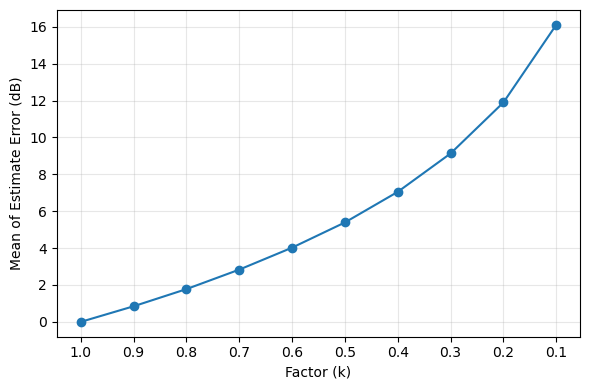

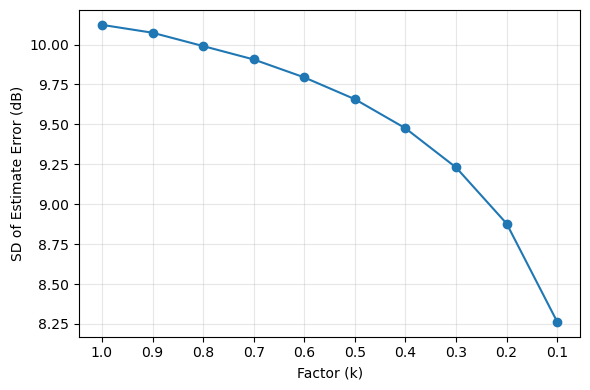

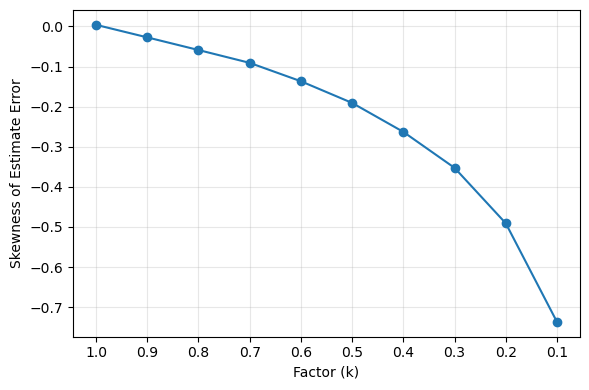

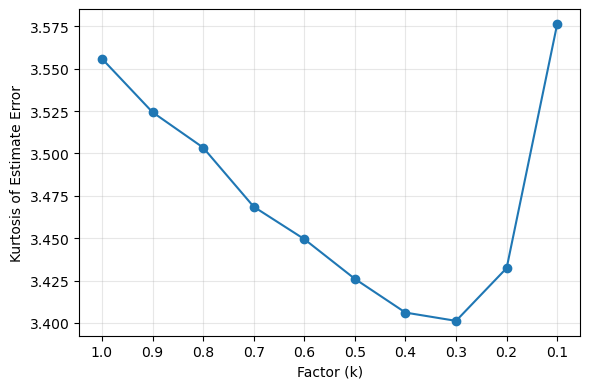

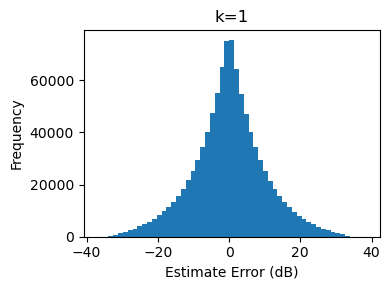

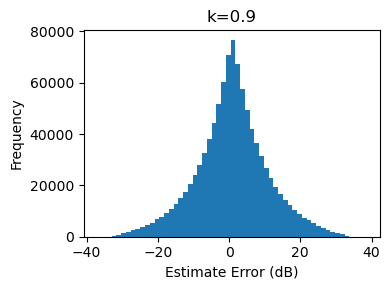

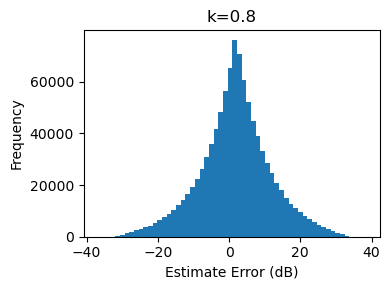

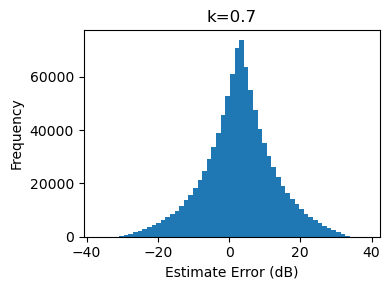

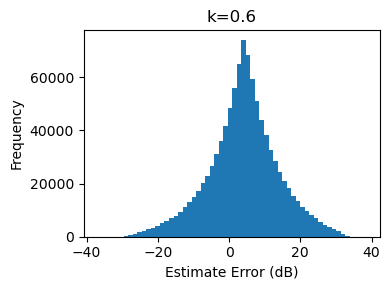

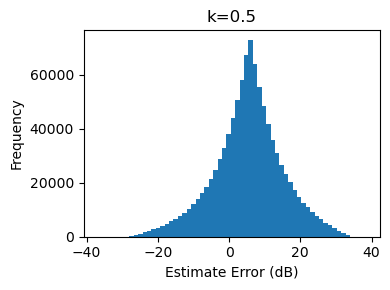

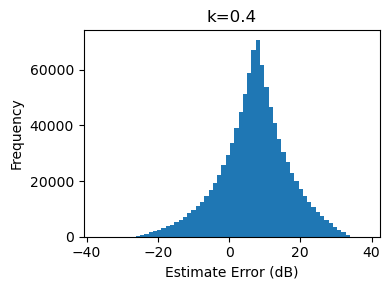

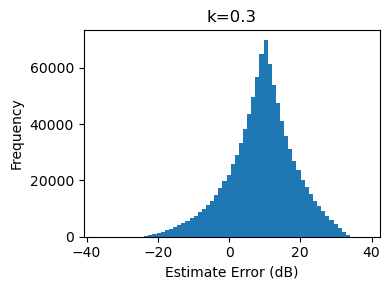

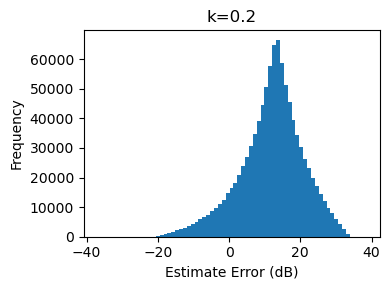

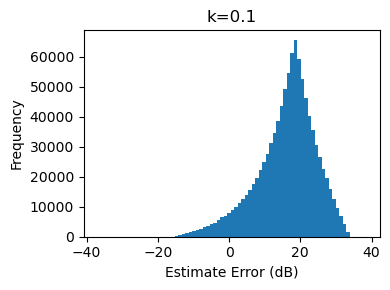



==================== DWD ====================

Summary metrics:

k = 1
  Mean distance A               = 24.917
  Mean distance B               = 24.931
  Mean of Estimate Error        = -0.0019 dB
  SD of Estimate Error          = 11.2538 dB
  Skewness of Estimate Error    = 0.0006
  Kurtosis of Estimate Error    = 3.0987

k = 0.9
  Mean distance A               = 24.917
  Mean distance B               = 22.558
  Mean of Estimate Error        = 0.8187 dB
  SD of Estimate Error          = 11.1858 dB
  Skewness of Estimate Error    = -0.0188
  Kurtosis of Estimate Error    = 3.0822

k = 0.8
  Mean distance A               = 24.917
  Mean distance B               = 20.153
  Mean of Estimate Error        = 1.7309 dB
  SD of Estimate Error          = 11.0944 dB
  Skewness of Estimate Error    = -0.0470
  Kurtosis of Estimate Error    = 3.0606

k = 0.7
  Mean distance A               = 24.917
  Mean distance B               = 17.736
  Mean of Estimate Error        = 2.7717 dB
  SD of Esti

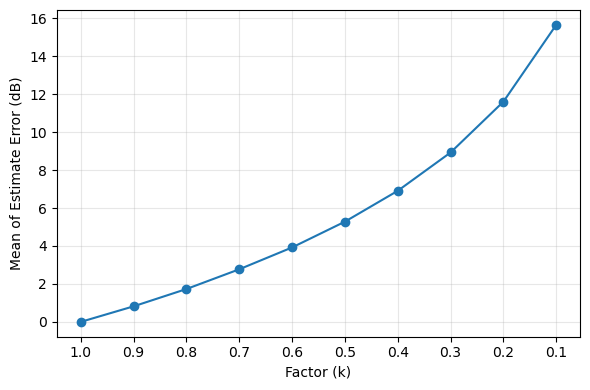

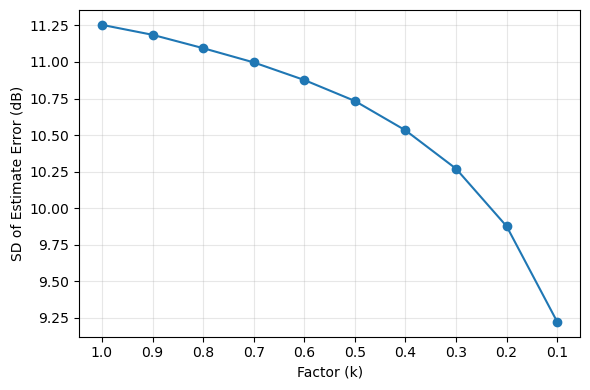

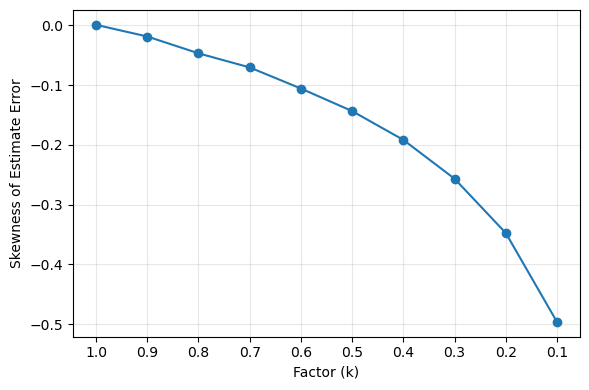

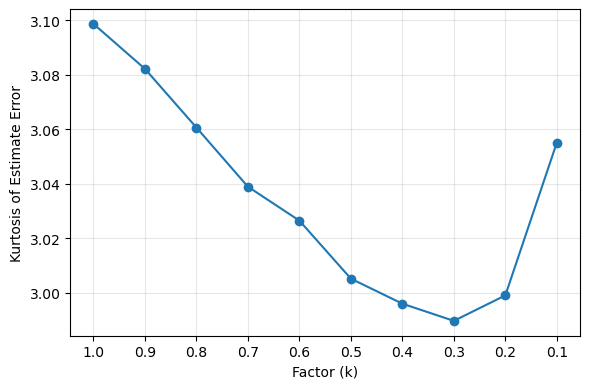

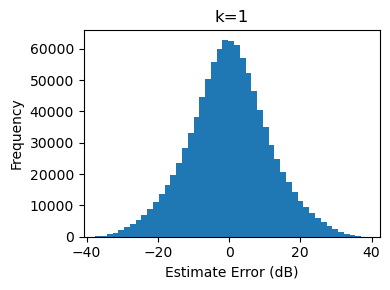

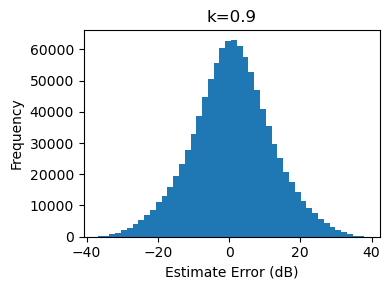

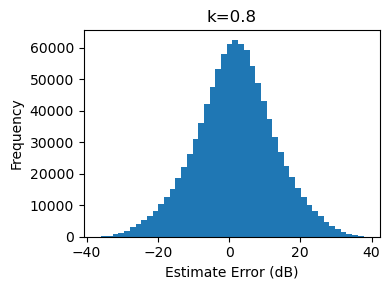

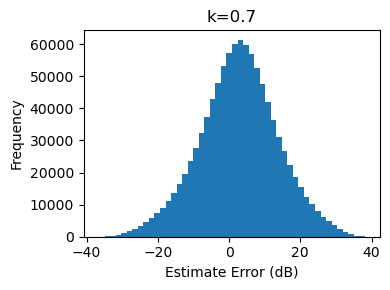

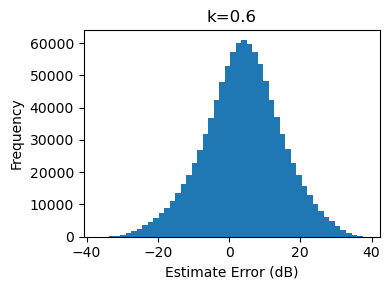

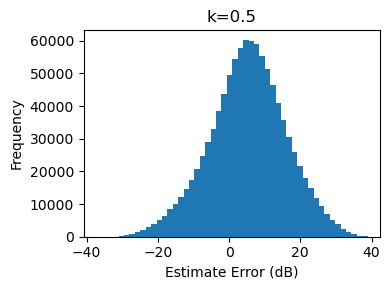

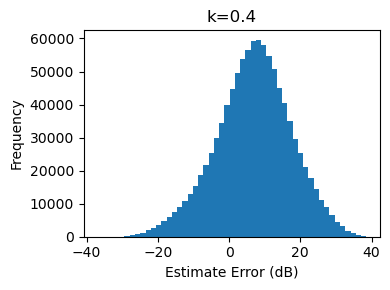

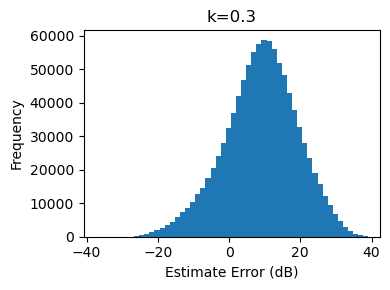

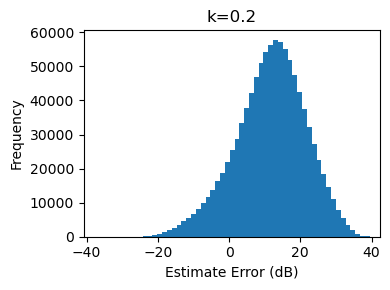

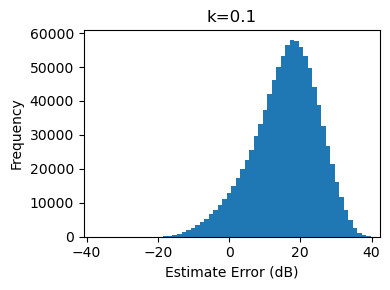

In [14]:
distr_list = ["uniform", "dwd"]

all_dif_X = np.concatenate(
	[results[distr][k]["dif_X"] for k in k_list]
)
xmin = all_dif_X.min()
xmax = all_dif_X.max()

for distr in distr_list:
	print(f"\n\n==================== {distr.upper()} ====================\n")

	# Summary metrics
	print("Summary metrics:\n")
	for k in k_list:
		res = results[distr][k]
		print(f"k = {k}")
		print(f"  Mean distance A               = {res['rA_mean']:.3f}")
		print(f"  Mean distance B               = {res['rB_mean']:.3f}")
		print(f"  Mean of Estimate Error        = {res['mean']:.4f} dB")
		print(f"  SD of Estimate Error          = {res['sd']:.4f} dB")
		print(f"  Skewness of Estimate Error    = {res['skew']:.4f}")
		print(f"  Kurtosis of Estimate Error    = {res['kurt']:.4f}")
		print()

	# Mean vs k
	plt.figure(figsize=(6, 4))
	plt.plot(k_list, [results[distr][k]["mean"] for k in k_list], marker="o")
	plt.gca().invert_xaxis()
	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of Estimate Error (dB)")
	# plt.title(f"{distr}: Mean of Estimate Error vs k")
	plt.grid(alpha=0.3)
	plt.xticks(k_list)
	plt.tight_layout()
	plt.show()

	# SD vs k
	plt.figure(figsize=(6, 4))
	plt.plot(k_list, [results[distr][k]["sd"] for k in k_list], marker="o")
	plt.gca().invert_xaxis()
	plt.xlabel("Factor (k)")
	plt.ylabel("SD of Estimate Error (dB)")
	# plt.title(f"{distr}: SD of Estimate Error vs k")
	plt.grid(alpha=0.3)
	plt.xticks(k_list)
	plt.tight_layout()
	plt.show()

	# Skew vs k
	plt.figure(figsize=(6, 4))
	plt.plot(k_list, [results[distr][k]["skew"] for k in k_list], marker="o")
	plt.gca().invert_xaxis()
	plt.xlabel("Factor (k)")
	plt.ylabel("Skewness of Estimate Error")
	# plt.title(f"{distr}: Skewness of Estimate Error vs k")
	plt.grid(alpha=0.3)
	plt.xticks(k_list)
	plt.tight_layout()
	plt.show()

	# Kurt vs k
	plt.figure(figsize=(6, 4))
	plt.plot(k_list, [results[distr][k]["kurt"] for k in k_list], marker="o")
	plt.gca().invert_xaxis()
	plt.xlabel("Factor (k)")
	plt.ylabel("Kurtosis of Estimate Error")
	# plt.title(f"{distr}: Kurtosis of Estimate Error vs k")
	plt.grid(alpha=0.3)
	plt.xticks(k_list)
	plt.tight_layout()
	plt.show()

	# Histograms
	for k in k_list:
		dif_X = results[distr][k]["dif_X"]
		plt.figure(figsize=(4, 3))
		plt.hist(dif_X, bins=50)
		plt.xlim(xmin, xmax)
		plt.xlabel("Estimate Error (dB)")
		plt.ylabel("Frequency")
		plt.title(f"k={k}")
		plt.tight_layout()
		plt.show()

#### Regression Models for Correction

##### Modelo 1: bias ≈ b0 + b1*skew + b2*kurt


Distribution: uniform
Summary (before correction):

k = 1.0  bias = -0.0030 dB  skew = 0.0041  kurtosis = 3.5559
k = 0.9  bias = 0.8440 dB  skew = -0.0272  kurtosis = 3.5243
k = 0.8  bias = 1.7754 dB  skew = -0.0587  kurtosis = 3.5034
k = 0.7  bias = 2.8322 dB  skew = -0.0907  kurtosis = 3.4685
k = 0.6  bias = 4.0237 dB  skew = -0.1366  kurtosis = 3.4494
k = 0.5  bias = 5.3912 dB  skew = -0.1906  kurtosis = 3.4260
k = 0.4  bias = 7.0503 dB  skew = -0.2628  kurtosis = 3.4061
k = 0.3  bias = 9.1329 dB  skew = -0.3525  kurtosis = 3.4012
k = 0.2  bias = 11.8984 dB  skew = -0.4907  kurtosis = 3.4323
k = 0.1  bias = 16.1104 dB  skew = -0.7366  kurtosis = 3.5764

Fitted correction model:

bias ≈ 30.203199 + -22.017905 * skew + -8.477800 * kurtosis

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0030 dB  bias_corr_1 = -0.0330 dB  corrected_mean_1 = 0.0300 dB
k = 0.9  raw_mean = 0.8440 dB  bias_corr_1 = 0.9230 dB  corrected_mean_1 = -0.0790 dB
k = 0.8  raw_mean = 1.7754 dB  bias_co

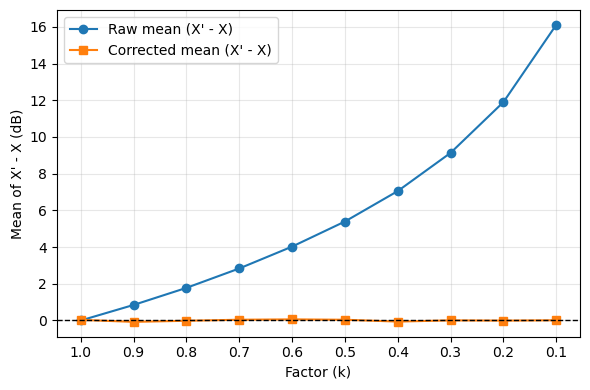


Distribution: dwd
Summary (before correction):

k = 1.0  bias = -0.0019 dB  skew = 0.0006  kurtosis = 3.0987
k = 0.9  bias = 0.8187 dB  skew = -0.0188  kurtosis = 3.0822
k = 0.8  bias = 1.7309 dB  skew = -0.0470  kurtosis = 3.0606
k = 0.7  bias = 2.7717 dB  skew = -0.0705  kurtosis = 3.0389
k = 0.6  bias = 3.9232 dB  skew = -0.1058  kurtosis = 3.0265
k = 0.5  bias = 5.2827 dB  skew = -0.1435  kurtosis = 3.0052
k = 0.4  bias = 6.9095 dB  skew = -0.1917  kurtosis = 2.9960
k = 0.3  bias = 8.9300 dB  skew = -0.2566  kurtosis = 2.9897
k = 0.2  bias = 11.6098 dB  skew = -0.3473  kurtosis = 2.9991
k = 0.1  bias = 15.6614 dB  skew = -0.4960  kurtosis = 3.0551

Fitted correction model:

bias ≈ 29.000976 + -30.718421 * skew + -9.352828 * kurtosis

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0019 dB  bias_corr_1 = 0.0000 dB  corrected_mean_1 = -0.0019 dB
k = 0.9  raw_mean = 0.8187 dB  bias_corr_1 = 0.7527 dB  corrected_mean_1 = 0.0660 dB
k = 0.8  raw_mean = 1.7309 dB  bias_corr_1 

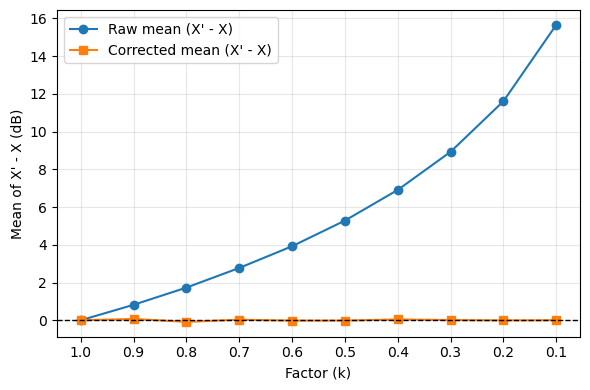

In [15]:
correction_models_1 = {}  # will contain (beta0, beta1, beta2) for each distr

for distr in distr_list:


	bias_list = []
	skew_list = []
	kurt_list = []

	for k in k_list:
		res = results[distr][k]

		bias = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		results[distr][k]["bias"] = bias

		bias_list.append(bias)
		skew_list.append(skew)
		kurt_list.append(kurt)


	### BEFORE correction summary

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Summary (before correction):\n")

	for k in k_list:
		res = results[distr][k]
		print(
			f"k = {k:.1f}  "
			f"bias = {res['bias']:.4f} dB  "
			f"skew = {res['skew']:.4f}  "
			f"kurtosis = {res['kurt']:.4f}"
		)


	### Multiple linear regression: bias ≈ b0 + b1*skew + b2*kurt

	X_mat = np.column_stack([
		np.ones(len(k_list)),        # intercept
		np.array(skew_list),         # skew
		np.array(kurt_list),         # kurt
	])
	y_vec = np.array(bias_list)

	beta, residuals, rank, s = np.linalg.lstsq(X_mat, y_vec, rcond=None)
	beta0, beta1, beta2 = beta

	correction_models_1[distr] = (beta0, beta1, beta2)

	print("\nFitted correction model:\n")
	print(f"bias ≈ {beta0:.6f} + {beta1:.6f} * skew + {beta2:.6f} * kurtosis\n")


	### AFTER correction summary

	print("Raw vs Corrected means for each k:\n")

	for k in k_list:
		res = results[distr][k]

		mean_raw = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		bias_corr_1 = beta0 + beta1 * skew + beta2 * kurt
		mean_corr_1 = mean_raw - bias_corr_1

		results[distr][k]["bias_corr_1"] = bias_corr_1
		results[distr][k]["mean_corr_1"] = mean_corr_1

		print(
			f"k = {k:.1f}  "
			f"raw_mean = {mean_raw:.4f} dB  "
			f"bias_corr_1 = {bias_corr_1:.4f} dB  "
			f"corrected_mean_1 = {mean_corr_1:.4f} dB"
		)


	### Plot raw vs corrected

	raw_bias = [results[distr][k]["mean"] for k in k_list]
	corr_bias_1 = [results[distr][k]["mean_corr_1"] for k in k_list]

	plt.figure(figsize=(6, 4))
	plt.plot(k_list, raw_bias, marker="o", label="Raw mean (X' - X)")
	plt.plot(k_list, corr_bias_1, marker="s", label="Corrected mean (X' - X)")
	plt.axhline(0, linestyle="--", linewidth=1, color="black")

	plt.gca().invert_xaxis()
	plt.xticks(k_list)  # show all k values
	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")
	# plt.title(f"{distr}: Raw vs Corrected estimates of X' - X")
	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

##### Modelo 2: bias ≈ b0 + b1*skew + b2*kurt + b3*(skew*kurt)


Distribution: uniform
Summary (before correction):

k = 1.0  bias = -0.0030 dB  skew = 0.0041  kurtosis = 3.5559
k = 0.9  bias = 0.8440 dB  skew = -0.0272  kurtosis = 3.5243
k = 0.8  bias = 1.7754 dB  skew = -0.0587  kurtosis = 3.5034
k = 0.7  bias = 2.8322 dB  skew = -0.0907  kurtosis = 3.4685
k = 0.6  bias = 4.0237 dB  skew = -0.1366  kurtosis = 3.4494
k = 0.5  bias = 5.3912 dB  skew = -0.1906  kurtosis = 3.4260
k = 0.4  bias = 7.0503 dB  skew = -0.2628  kurtosis = 3.4061
k = 0.3  bias = 9.1329 dB  skew = -0.3525  kurtosis = 3.4012
k = 0.2  bias = 11.8984 dB  skew = -0.4907  kurtosis = 3.4323
k = 0.1  bias = 16.1104 dB  skew = -0.7366  kurtosis = 3.5764

Fitted correction model with interaction:

bias ≈ 31.472331 + -18.353790 * skew + -8.838992 * kurtosis + -1.037092 * (skew * kurtosis)

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0030 dB  bias_corr_2 = -0.0483 dB  corrected_mean_2 = 0.0453 dB
k = 0.9  raw_mean = 0.8440 dB  bias_corr_2 = 0.9189 dB  corrected_mean_2 = 

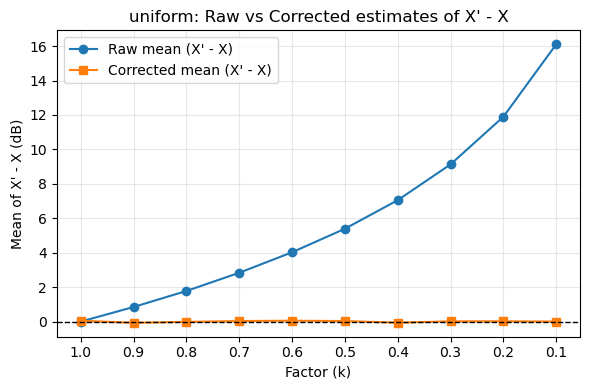


Distribution: dwd
Summary (before correction):

k = 1.0  bias = -0.0019 dB  skew = 0.0006  kurtosis = 3.0987
k = 0.9  bias = 0.8187 dB  skew = -0.0188  kurtosis = 3.0822
k = 0.8  bias = 1.7309 dB  skew = -0.0470  kurtosis = 3.0606
k = 0.7  bias = 2.7717 dB  skew = -0.0705  kurtosis = 3.0389
k = 0.6  bias = 3.9232 dB  skew = -0.1058  kurtosis = 3.0265
k = 0.5  bias = 5.2827 dB  skew = -0.1435  kurtosis = 3.0052
k = 0.4  bias = 6.9095 dB  skew = -0.1917  kurtosis = 2.9960
k = 0.3  bias = 8.9300 dB  skew = -0.2566  kurtosis = 2.9897
k = 0.2  bias = 11.6098 dB  skew = -0.3473  kurtosis = 2.9991
k = 0.1  bias = 15.6614 dB  skew = -0.4960  kurtosis = 3.0551

Fitted correction model with interaction:

bias ≈ 28.290554 + -35.223793 * skew + -9.121236 * kurtosis + 1.476841 * (skew * kurtosis)

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0019 dB  bias_corr_2 = 0.0073 dB  corrected_mean_2 = -0.0091 dB
k = 0.9  raw_mean = 0.8187 dB  bias_corr_2 = 0.7552 dB  corrected_mean_2 = 0.063

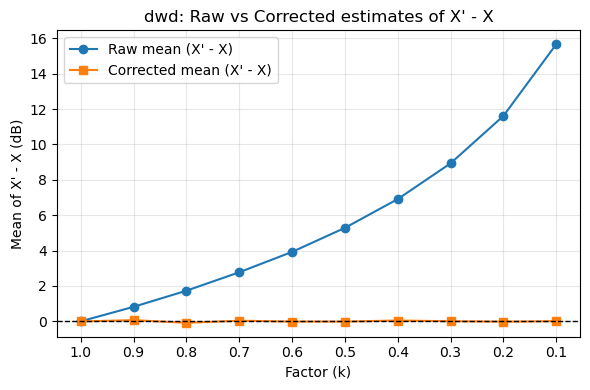

In [16]:
correction_models_2 = {}  # will contain (beta0, beta1, beta2, beta3) for each distr

for distr in distr_list:

	bias_list = []
	skew_list = []
	kurt_list = []

	for k in k_list:
		res = results[distr][k]

		bias = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		results[distr][k]["bias"] = bias

		bias_list.append(bias)
		skew_list.append(skew)
		kurt_list.append(kurt)

	### BEFORE correction summary

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Summary (before correction):\n")

	for k in k_list:
		res = results[distr][k]
		print(
			f"k = {k:.1f}  "
			f"bias = {res['bias']:.4f} dB  "
			f"skew = {res['skew']:.4f}  "
			f"kurtosis = {res['kurt']:.4f}"
		)

	### Multiple linear regression with interaction:
	### bias ≈ b0 + b1*skew + b2*kurt + b3*(skew*kurt)

	skew_arr = np.array(skew_list)
	kurt_arr = np.array(kurt_list)
	interaction_arr = skew_arr * kurt_arr

	X_mat = np.column_stack([
		np.ones(len(k_list)),   # intercept
		skew_arr,               # skew
		kurt_arr,               # kurt
		interaction_arr         # interaction skew*kurt
	])
	y_vec = np.array(bias_list)

	beta, residuals, rank, s = np.linalg.lstsq(X_mat, y_vec, rcond=None)
	beta0, beta1, beta2, beta3 = beta

	correction_models_2[distr] = (beta0, beta1, beta2, beta3)

	print("\nFitted correction model with interaction:\n")
	print(
		f"bias ≈ {beta0:.6f} "
		f"+ {beta1:.6f} * skew "
		f"+ {beta2:.6f} * kurtosis "
		f"+ {beta3:.6f} * (skew * kurtosis)\n"
	)

	### AFTER correction summary

	print("Raw vs Corrected means for each k:\n")

	for k in k_list:
		res = results[distr][k]

		mean_raw = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		bias_corr_2 = beta0 + beta1 * skew + beta2 * kurt + beta3 * (skew * kurt)
		mean_corr_2 = mean_raw - bias_corr_2

		results[distr][k]["bias_corr_2"] = bias_corr_2
		results[distr][k]["mean_corr_2"] = mean_corr_2

		print(
			f"k = {k:.1f}  "
			f"raw_mean = {mean_raw:.4f} dB  "
			f"bias_corr_2 = {bias_corr_2:.4f} dB  "
			f"corrected_mean_2 = {mean_corr_2:.4f} dB"
		)

	### Plot raw vs corrected

	raw_bias = [results[distr][k]["mean"] for k in k_list]
	corr_bias_2 = [results[distr][k]["mean_corr_2"] for k in k_list]

	plt.figure(figsize=(6, 4))
	plt.plot(k_list, raw_bias, marker="o", label="Raw mean (X' - X)")
	plt.plot(k_list, corr_bias_2, marker="s", label="Corrected mean (X' - X)")
	plt.axhline(0, linestyle="--", linewidth=1, color="black")

	plt.gca().invert_xaxis()
	plt.xticks(k_list)
	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")
	plt.title(f"{distr}: Raw vs Corrected estimates of X' - X")
	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

##### Modelo 3: bias ≈ b0 + b1*skew + b2*kurt + b3*(skew*kurt) + b4*skew² + b5*kurt²


Distribution: uniform
Summary (before correction):

k = 1.0  bias = -0.0030 dB  skew = 0.0041  kurtosis = 3.5559
k = 0.9  bias = 0.8440 dB  skew = -0.0272  kurtosis = 3.5243
k = 0.8  bias = 1.7754 dB  skew = -0.0587  kurtosis = 3.5034
k = 0.7  bias = 2.8322 dB  skew = -0.0907  kurtosis = 3.4685
k = 0.6  bias = 4.0237 dB  skew = -0.1366  kurtosis = 3.4494
k = 0.5  bias = 5.3912 dB  skew = -0.1906  kurtosis = 3.4260
k = 0.4  bias = 7.0503 dB  skew = -0.2628  kurtosis = 3.4061
k = 0.3  bias = 9.1329 dB  skew = -0.3525  kurtosis = 3.4012
k = 0.2  bias = 11.8984 dB  skew = -0.4907  kurtosis = 3.4323
k = 0.1  bias = 16.1104 dB  skew = -0.7366  kurtosis = 3.5764

Fitted correction model with interaction + quadratic terms:

bias ≈ 15.581644 + -19.573422 * skew + 1.489999 * kurtosis + -0.360483 * (skew * kurtosis) + 1.699135 * skew² + -1.648769 * kurtosis²

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0030 dB  bias_corr_3 = -0.0530 dB  corrected_mean_3 = 0.0500 dB
k = 0.9  raw_me

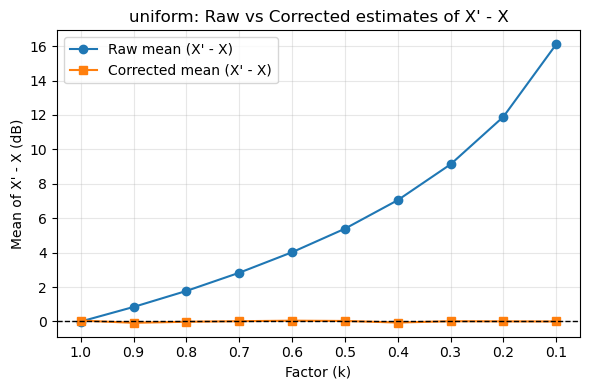


Distribution: dwd
Summary (before correction):

k = 1.0  bias = -0.0019 dB  skew = 0.0006  kurtosis = 3.0987
k = 0.9  bias = 0.8187 dB  skew = -0.0188  kurtosis = 3.0822
k = 0.8  bias = 1.7309 dB  skew = -0.0470  kurtosis = 3.0606
k = 0.7  bias = 2.7717 dB  skew = -0.0705  kurtosis = 3.0389
k = 0.6  bias = 3.9232 dB  skew = -0.1058  kurtosis = 3.0265
k = 0.5  bias = 5.2827 dB  skew = -0.1435  kurtosis = 3.0052
k = 0.4  bias = 6.9095 dB  skew = -0.1917  kurtosis = 2.9960
k = 0.3  bias = 8.9300 dB  skew = -0.2566  kurtosis = 2.9897
k = 0.2  bias = 11.6098 dB  skew = -0.3473  kurtosis = 2.9991
k = 0.1  bias = 15.6614 dB  skew = -0.4960  kurtosis = 3.0551

Fitted correction model with interaction + quadratic terms:

bias ≈ 229.851220 + -29.556559 * skew + -136.955783 * kurtosis + 0.795337 * (skew * kurtosis) + 6.623669 * skew² + 20.264372 * kurtosis²

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0019 dB  bias_corr_3 = 0.0267 dB  corrected_mean_3 = -0.0286 dB
k = 0.9  raw_mea

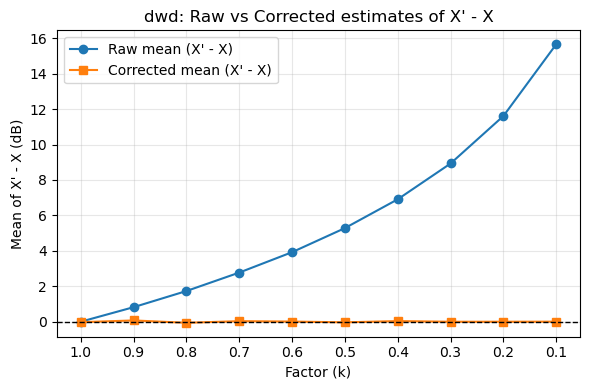

In [17]:
correction_models_3 = {}  # will contain (beta0, beta1, beta2, beta3, beta4, beta5) for each distr

for distr in distr_list:

	bias_list = []
	skew_list = []
	kurt_list = []

	for k in k_list:
		res = results[distr][k]

		bias = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		results[distr][k]["bias"] = bias

		bias_list.append(bias)
		skew_list.append(skew)
		kurt_list.append(kurt)

	### BEFORE correction summary

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Summary (before correction):\n")

	for k in k_list:
		res = results[distr][k]
		print(
			f"k = {k:.1f}  "
			f"bias = {res['bias']:.4f} dB  "
			f"skew = {res['skew']:.4f}  "
			f"kurtosis = {res['kurt']:.4f}"
		)

	### Multiple regression with interaction + quadratic terms:
	### bias ≈ b0 + b1*skew + b2*kurt + b3*(skew*kurt) + b4*skew² + b5*kurt²

	skew_arr = np.array(skew_list)
	kurt_arr = np.array(kurt_list)

	interaction_arr = skew_arr * kurt_arr
	skew_sq_arr = skew_arr**2
	kurt_sq_arr = kurt_arr**2

	X_mat = np.column_stack([
		np.ones(len(k_list)),   # intercept
		skew_arr,               # skew
		kurt_arr,               # kurt
		interaction_arr,        # skew*kurt
		skew_sq_arr,            # skew^2
		kurt_sq_arr             # kurt^2
	])
	y_vec = np.array(bias_list)

	beta, residuals, rank, s = np.linalg.lstsq(X_mat, y_vec, rcond=None)
	beta0, beta1, beta2, beta3, beta4, beta5 = beta

	correction_models_3[distr] = (beta0, beta1, beta2, beta3, beta4, beta5)

	print("\nFitted correction model with interaction + quadratic terms:\n")
	print(
		f"bias ≈ {beta0:.6f} "
		f"+ {beta1:.6f} * skew "
		f"+ {beta2:.6f} * kurtosis "
		f"+ {beta3:.6f} * (skew * kurtosis) "
		f"+ {beta4:.6f} * skew² "
		f"+ {beta5:.6f} * kurtosis²\n"
	)

	### AFTER correction summary

	print("Raw vs Corrected means for each k:\n")

	for k in k_list:
		res = results[distr][k]

		mean_raw = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		bias_corr_3 = (
			beta0
			+ beta1 * skew
			+ beta2 * kurt
			+ beta3 * (skew * kurt)
			+ beta4 * (skew**2)
			+ beta5 * (kurt**2)
		)

		mean_corr_3 = mean_raw - bias_corr_3

		results[distr][k]["bias_corr_3"] = bias_corr_3
		results[distr][k]["mean_corr_3"] = mean_corr_3

		print(
			f"k = {k:.1f}  "
			f"raw_mean = {mean_raw:.4f} dB  "
			f"bias_corr_3 = {bias_corr_3:.4f} dB  "
			f"corrected_mean_3 = {mean_corr_3:.4f} dB"
		)

	### Plot raw vs corrected

	raw_bias = [results[distr][k]["mean"] for k in k_list]
	corr_bias_3 = [results[distr][k]["mean_corr_3"] for k in k_list]

	plt.figure(figsize=(6, 4))
	plt.plot(k_list, raw_bias, marker="o", label="Raw mean (X' - X)")
	plt.plot(k_list, corr_bias_3, marker="s", label="Corrected mean (X' - X)")
	plt.axhline(0, linestyle="--", linewidth=1, color="black")

	plt.gca().invert_xaxis()
	plt.xticks(k_list)
	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")
	plt.title(f"{distr}: Raw vs Corrected estimates of X' - X")
	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

##### Modelo 4: bias ≈ b0 + b1*skew + b2*kurt + b3*(skew*kurt) + b4*skew² + b5*kurt² + b6*skew³ + b7*kurt³


Distribution: uniform
Summary (before correction):

k = 1.0  bias = -0.0030 dB  skew = 0.0041  kurtosis = 3.5559
k = 0.9  bias = 0.8440 dB  skew = -0.0272  kurtosis = 3.5243
k = 0.8  bias = 1.7754 dB  skew = -0.0587  kurtosis = 3.5034
k = 0.7  bias = 2.8322 dB  skew = -0.0907  kurtosis = 3.4685
k = 0.6  bias = 4.0237 dB  skew = -0.1366  kurtosis = 3.4494
k = 0.5  bias = 5.3912 dB  skew = -0.1906  kurtosis = 3.4260
k = 0.4  bias = 7.0503 dB  skew = -0.2628  kurtosis = 3.4061
k = 0.3  bias = 9.1329 dB  skew = -0.3525  kurtosis = 3.4012
k = 0.2  bias = 11.8984 dB  skew = -0.4907  kurtosis = 3.4323
k = 0.1  bias = 16.1104 dB  skew = -0.7366  kurtosis = 3.5764

Fitted correction model with interaction + quadratic + cubic terms:

bias ≈ -28717.136209 + -1379.486408 * skew + 24307.370353 * kurtosis + 376.980267 * (skew * kurtosis) + -315.713203 * skew² + -6862.547963 * kurtosis² + -410.049683 * skew³ + 646.223330 * kurtosis³

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0030 dB

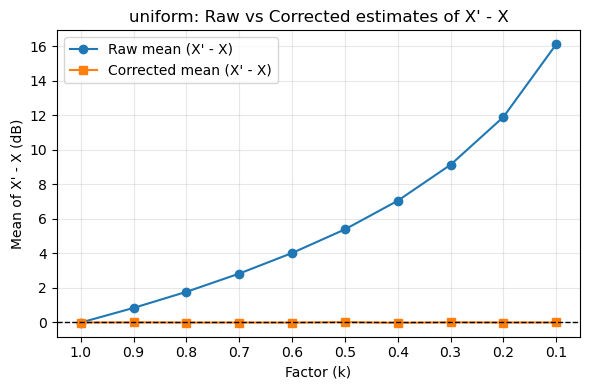


Distribution: dwd
Summary (before correction):

k = 1.0  bias = -0.0019 dB  skew = 0.0006  kurtosis = 3.0987
k = 0.9  bias = 0.8187 dB  skew = -0.0188  kurtosis = 3.0822
k = 0.8  bias = 1.7309 dB  skew = -0.0470  kurtosis = 3.0606
k = 0.7  bias = 2.7717 dB  skew = -0.0705  kurtosis = 3.0389
k = 0.6  bias = 3.9232 dB  skew = -0.1058  kurtosis = 3.0265
k = 0.5  bias = 5.2827 dB  skew = -0.1435  kurtosis = 3.0052
k = 0.4  bias = 6.9095 dB  skew = -0.1917  kurtosis = 2.9960
k = 0.3  bias = 8.9300 dB  skew = -0.2566  kurtosis = 2.9897
k = 0.2  bias = 11.6098 dB  skew = -0.3473  kurtosis = 2.9991
k = 0.1  bias = 15.6614 dB  skew = -0.4960  kurtosis = 3.0551

Fitted correction model with interaction + quadratic + cubic terms:

bias ≈ 9287.831744 + 918.024518 * skew + -8670.314435 * kurtosis + -300.456452 * (skew * kurtosis) + 239.379207 * skew² + 2703.184319 * kurtosis² + 365.565278 * skew³ + -281.543479 * kurtosis³

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0019 dB  bias_co

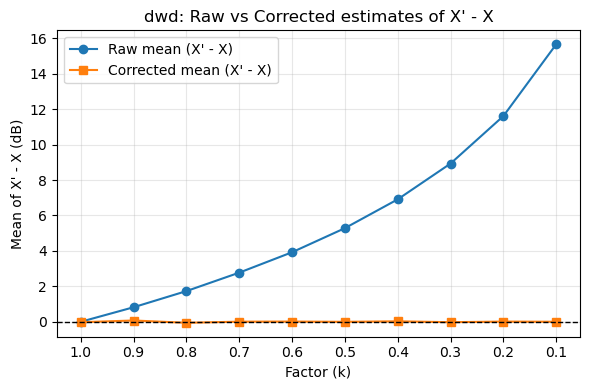

In [18]:
correction_models_4 = {}  # will contain (beta0, beta1, beta2, beta3, beta4, beta5, beta6, beta7) for each distr

for distr in distr_list:

	bias_list = []
	skew_list = []
	kurt_list = []

	for k in k_list:
		res = results[distr][k]

		bias = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		results[distr][k]["bias"] = bias

		bias_list.append(bias)
		skew_list.append(skew)
		kurt_list.append(kurt)

	### BEFORE correction summary

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Summary (before correction):\n")

	for k in k_list:
		res = results[distr][k]
		print(
			f"k = {k:.1f}  "
			f"bias = {res['bias']:.4f} dB  "
			f"skew = {res['skew']:.4f}  "
			f"kurtosis = {res['kurt']:.4f}"
		)

	### Multiple regression with interaction + quadratic + cubic terms:
	### bias ≈ b0 + b1*skew + b2*kurt + b3*(skew*kurt)
	###       + b4*skew² + b5*kurt² + b6*skew³ + b7*kurt³

	skew_arr = np.array(skew_list)
	kurt_arr = np.array(kurt_list)

	interaction_arr = skew_arr * kurt_arr
	skew_sq_arr = skew_arr**2
	kurt_sq_arr = kurt_arr**2
	skew_cu_arr = skew_arr**3
	kurt_cu_arr = kurt_arr**3

	X_mat = np.column_stack([
		np.ones(len(k_list)),   # intercept
		skew_arr,               # skew
		kurt_arr,               # kurt
		interaction_arr,        # skew*kurt
		skew_sq_arr,            # skew^2
		kurt_sq_arr,            # kurt^2
		skew_cu_arr,            # skew^3
		kurt_cu_arr             # kurt^3
	])
	y_vec = np.array(bias_list)

	beta, residuals, rank, s = np.linalg.lstsq(X_mat, y_vec, rcond=None)
	beta0, beta1, beta2, beta3, beta4, beta5, beta6, beta7 = beta

	correction_models_4[distr] = (beta0, beta1, beta2, beta3, beta4, beta5, beta6, beta7)

	print("\nFitted correction model with interaction + quadratic + cubic terms:\n")
	print(
		f"bias ≈ {beta0:.6f} "
		f"+ {beta1:.6f} * skew "
		f"+ {beta2:.6f} * kurtosis "
		f"+ {beta3:.6f} * (skew * kurtosis) "
		f"+ {beta4:.6f} * skew² "
		f"+ {beta5:.6f} * kurtosis² "
		f"+ {beta6:.6f} * skew³ "
		f"+ {beta7:.6f} * kurtosis³\n"
	)

	### AFTER correction summary

	print("Raw vs Corrected means for each k:\n")

	for k in k_list:
		res = results[distr][k]

		mean_raw = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		bias_corr_4 = (
			beta0
			+ beta1 * skew
			+ beta2 * kurt
			+ beta3 * (skew * kurt)
			+ beta4 * (skew**2)
			+ beta5 * (kurt**2)
			+ beta6 * (skew**3)
			+ beta7 * (kurt**3)
		)

		mean_corr_4 = mean_raw - bias_corr_4

		results[distr][k]["bias_corr_4"] = bias_corr_4
		results[distr][k]["mean_corr_4"] = mean_corr_4

		print(
			f"k = {k:.1f}  "
			f"raw_mean = {mean_raw:.4f} dB  "
			f"bias_corr_4 = {bias_corr_4:.4f} dB  "
			f"corrected_mean_4 = {mean_corr_4:.4f} dB"
		)

	### Plot raw vs corrected

	raw_bias = [results[distr][k]["mean"] for k in k_list]
	corr_bias_4 = [results[distr][k]["mean_corr_4"] for k in k_list]

	plt.figure(figsize=(6, 4))
	plt.plot(k_list, raw_bias, marker="o", label="Raw mean (X' - X)")
	plt.plot(k_list, corr_bias_4, marker="s", label="Corrected mean (X' - X)")
	plt.axhline(0, linestyle="--", linewidth=1, color="black")

	plt.gca().invert_xaxis()
	plt.xticks(k_list)
	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")
	plt.title(f"{distr}: Raw vs Corrected estimates of X' - X")
	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

#### Correction Evaluation

In [19]:
model_performance = {}
cv_predictions = {}


for distr in distr_list:

    # ==============================
    # Data
    # ==============================

    skew_arr = np.array([
        results[distr][k]["skew"]
        for k in k_list
    ])

    kurt_arr = np.array([
        results[distr][k]["kurt"]
        for k in k_list
    ])

    y = np.array([
        results[distr][k]["mean"]
        for k in k_list
    ])

    n = len(k_list)


    # ==============================
    # Matrix of the 4 models
    # ==============================

    X1 = np.column_stack([
        np.ones(n),
        skew_arr,
        kurt_arr
    ])

    X2 = np.column_stack([
        np.ones(n),
        skew_arr,
        kurt_arr,
        skew_arr * kurt_arr
    ])

    X3 = np.column_stack([
        np.ones(n),
        skew_arr,
        kurt_arr,
        skew_arr * kurt_arr,
        skew_arr**2,
        kurt_arr**2
    ])

    X4 = np.column_stack([
        np.ones(n),
        skew_arr,
        kurt_arr,
        skew_arr * kurt_arr,
        skew_arr**2,
        kurt_arr**2,
        skew_arr**3,
        kurt_arr**3
    ])

    X_models = {
        "Model 1": X1,
        "Model 2": X2,
        "Model 3": X3,
        "Model 4": X4
    }


    # ==============================
    # Baseline: no correction
    # ==============================

    raw_rmse = np.sqrt(
        np.mean(y**2)
    )


    # ==============================
    # Evaluation
    # ==============================

    performance_rows = []
    cv_predictions[distr] = {}

    for model_name, X in X_models.items():

        # --------------------------
        # Data fit on full data
        # --------------------------

        beta, residuals, rank, s = np.linalg.lstsq(
            X,
            y,
            rcond=None
        )

        y_hat_train = X @ beta

        corrected_train = (
            y - y_hat_train
        )

        train_rmse = np.sqrt(
            np.mean(corrected_train**2)
        )

        train_mae = np.mean(
            np.abs(corrected_train)
        )

        train_max_error = np.max(
            np.abs(corrected_train)
        )

        condition_number = np.linalg.cond(X)


        # ==========================
        # Leave-one-k-out CV (cross-validation)
        # ==========================

        cv_pred = np.empty(n)
        cv_residual = np.empty(n)

        for i in range(n):

            train_mask = np.ones(
                n,
                dtype=bool
            )

            train_mask[i] = False

            X_train = X[train_mask]
            y_train = y[train_mask]

            X_test = X[i:i+1]

            beta_cv, _, _, _ = np.linalg.lstsq(
                X_train,
                y_train,
                rcond=None
            )

            # Predicted bias for k (out-of-sample)
            predicted_bias = (
                X_test @ beta_cv
            )[0]

            cv_pred[i] = predicted_bias

            # Corrected value (out-of-sample)
            cv_residual[i] = (
                y[i]
                - predicted_bias
            )


        # ==========================
        # CV Metrics
        # ==========================

        cv_rmse = np.sqrt(
            np.mean(cv_residual**2)
        )

        cv_mae = np.mean(
            np.abs(cv_residual)
        )

        cv_max_error = np.max(
            np.abs(cv_residual)
        )

        cv_mean_bias = np.mean(
            cv_residual
        )

        improvement = (
            100
            * (1 - cv_rmse / raw_rmse)
        )

        cv_predictions[distr][model_name] = {
            "predicted_bias": cv_pred,
            "corrected": cv_residual
        }

        performance_rows.append({
            "Model": model_name,
            "N coefficients": X.shape[1],

            "Train RMSE": train_rmse,
            "Train MAE": train_mae,
            "Train Max Error": train_max_error,

            "CV RMSE": cv_rmse,
            "CV MAE": cv_mae,
            "CV Max Error": cv_max_error,
            "CV Mean Bias": cv_mean_bias,

            "Improvement vs raw (%)": improvement,

            "Rank": rank,
            "Condition number": condition_number
        })


    # ==============================
    # Table
    # ==============================

    performance_df = pd.DataFrame(
        performance_rows
    )

    performance_df = performance_df.sort_values(
        "CV RMSE"
    )

    model_performance[distr] = performance_df

    print("\n" + "=" * 80)
    print(f"Distribution: {distr}")
    print(f"Raw RMSE: {raw_rmse:.4f} dB\n")

    print(
        performance_df.to_string(
            index=False
        )
    )


Distribution: uniform
Raw RMSE: 7.6901 dB

  Model  N coefficients  Train RMSE  Train MAE  Train Max Error  CV RMSE   CV MAE  CV Max Error  CV Mean Bias  Improvement vs raw (%)  Rank  Condition number
Model 1               3    0.042001   0.034329         0.078961 0.060930 0.052093      0.106400      0.006701               99.207677     3      2.209167e+02
Model 2               4    0.040469   0.033052         0.074897 0.090674 0.071511      0.208112     -0.013757               98.820904     4      1.335426e+03
Model 3               6    0.040155   0.031829         0.077434 0.470651 0.227301      1.453036     -0.115357               93.879786     6      9.032540e+04
Model 4               8    0.009380   0.006913         0.018769 1.024283 0.388165      3.222587      0.284686               86.680509     8      4.369636e+07

Distribution: dwd
Raw RMSE: 7.4980 dB

  Model  N coefficients  Train RMSE  Train MAE  Train Max Error  CV RMSE   CV MAE  CV Max Error  CV Mean Bias  Improvement vs 

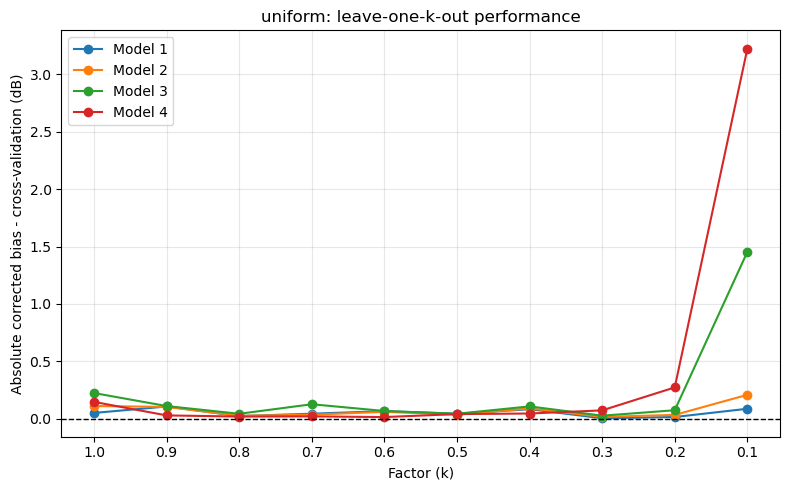

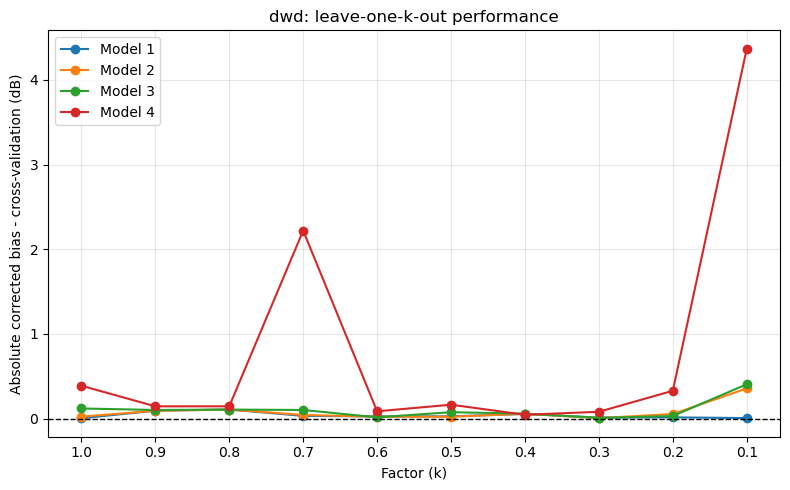

In [23]:
for distr in distr_list:

    plt.figure(figsize=(8, 5))

    for model_name in [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4"
    ]:

        corrected_cv = (
            cv_predictions[distr][model_name]["corrected"]
        )

        plt.plot(
            k_list,
            np.abs(corrected_cv),
            marker="o",
            label=model_name
        )

    plt.axhline(
        0,
        linestyle="--",
        color="black",
        linewidth=1
    )

    plt.gca().invert_xaxis()
    plt.xticks(k_list)

    plt.xlabel("Factor (k)")
    plt.ylabel(
        "Absolute corrected bias - cross-validation (dB)"
    )

    plt.title(
        f"{distr}: leave-one-k-out performance"
    )

    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

#### Correction Visualization


Distribution: uniform
Comparison of corrected means:

k = 1.0  raw = -0.0030 dB  corr_1 = 0.0300 dB  corr_2 = 0.0453 dB  corr_3 = 0.0500 dB  corr_4 = -0.0023 dB
k = 0.9  raw = 0.8440 dB  corr_1 = -0.0790 dB  corr_2 = -0.0749 dB  corr_3 = -0.0774 dB  corr_4 = 0.0066 dB
k = 0.8  raw = 1.7754 dB  corr_1 = -0.0186 dB  corr_2 = -0.0205 dB  corr_3 = -0.0180 dB  corr_4 = -0.0032 dB
k = 0.7  raw = 2.8322 dB  corr_1 = 0.0373 dB  corr_2 = 0.0271 dB  corr_3 = 0.0155 dB  corr_4 = -0.0018 dB
k = 0.6  raw = 4.0237 dB  corr_1 = 0.0569 dB  corr_2 = 0.0455 dB  corr_3 = 0.0455 dB  corr_4 = -0.0071 dB
k = 0.5  raw = 5.3912 dB  corr_1 = 0.0362 dB  corr_2 = 0.0257 dB  corr_3 = 0.0292 dB  corr_4 = 0.0188 dB
k = 0.4  raw = 7.0503 dB  corr_1 = -0.0635 dB  corr_2 = -0.0678 dB  corr_3 = -0.0627 dB  corr_4 = -0.0181 dB
k = 0.3  raw = 9.1329 dB  corr_1 = 0.0029 dB  corr_2 = 0.0104 dB  corr_3 = 0.0135 dB  corr_4 = 0.0091 dB
k = 0.2  raw = 11.8984 dB  corr_1 = -0.0106 dB  corr_2 = 0.0113 dB  corr_3 = 0.0054 dB  co

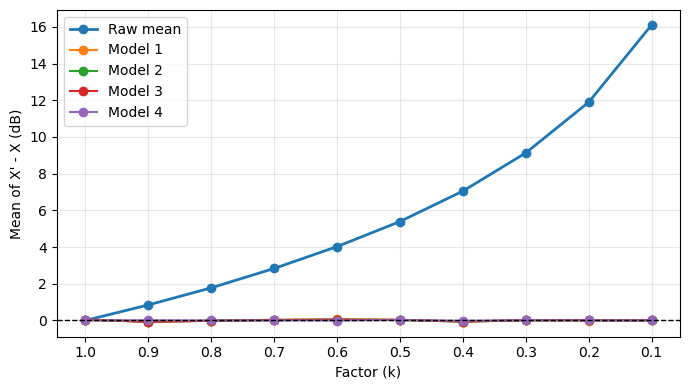


Distribution: dwd
Comparison of corrected means:

k = 1.0  raw = -0.0019 dB  corr_1 = -0.0019 dB  corr_2 = -0.0091 dB  corr_3 = -0.0286 dB  corr_4 = -0.0269 dB
k = 0.9  raw = 0.8187 dB  corr_1 = 0.0660 dB  corr_2 = 0.0635 dB  corr_3 = 0.0686 dB  corr_4 = 0.0699 dB
k = 0.8  raw = 1.7309 dB  corr_1 = -0.0875 dB  corr_2 = -0.0852 dB  corr_3 = -0.0636 dB  corr_4 = -0.0595 dB
k = 0.7  raw = 2.7717 dB  corr_1 = 0.0266 dB  corr_2 = 0.0320 dB  corr_3 = 0.0289 dB  corr_4 = 0.0043 dB
k = 0.6  raw = 3.9232 dB  corr_1 = -0.0221 dB  corr_2 = -0.0163 dB  corr_3 = 0.0059 dB  corr_4 = 0.0101 dB
k = 0.5  raw = 5.2827 dB  corr_1 = -0.0204 dB  corr_2 = -0.0156 dB  corr_3 = -0.0369 dB  corr_4 = -0.0047 dB
k = 0.4  raw = 6.9095 dB  corr_1 = 0.0418 dB  corr_2 = 0.0429 dB  corr_3 = 0.0329 dB  corr_4 = 0.0241 dB
k = 0.3  raw = 8.9300 dB  corr_1 = 0.0082 dB  corr_2 = 0.0031 dB  corr_3 = -0.0044 dB  corr_4 = -0.0251 dB
k = 0.2  raw = 11.6098 dB  corr_1 = -0.0101 dB  corr_2 = -0.0207 dB  corr_3 = -0.0034 dB  co

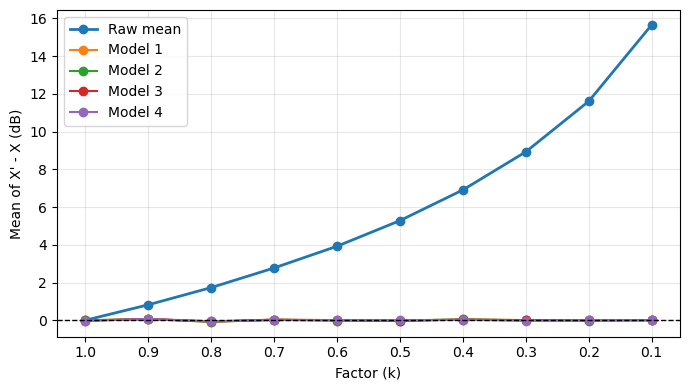

In [26]:
model_names = ["1", "2", "3", "4"]
# model_names = ["1", "3"]

for distr in distr_list:

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Comparison of corrected means:\n")

	for k in k_list:
		res = results[distr][k]

		line = f"k = {k:.1f}  raw = {res['mean']:.4f} dB"
		for model_name in model_names:
			line += f"  corr_{model_name} = {res[f'mean_corr_{model_name}']:.4f} dB"
		print(line)

	raw_bias = [results[distr][k]["mean"] for k in k_list]

	plt.figure(figsize=(7, 4))
	plt.plot(k_list, raw_bias, marker="o", linewidth=2, label="Raw mean")

	for model_name in model_names:
		corr_bias = [results[distr][k][f"mean_corr_{model_name}"] for k in k_list]
		plt.plot(k_list, corr_bias, marker="o", label=f"Model {model_name}")

	plt.axhline(0, linestyle="--", linewidth=1, color="black")
	plt.gca().invert_xaxis()
	plt.xticks(k_list)
	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")
	# plt.title(f"{distr}: comparison of correction models")
	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

Bias vs Skew

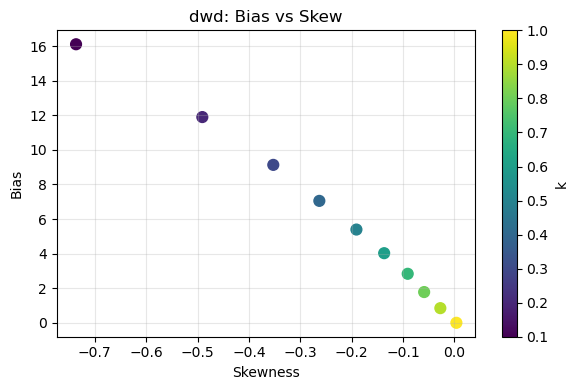

In [27]:
bias_all = []
skew_all = []
k_all = []

for k in k_list:
	res = results["uniform"][k]

	bias_all.append(res["bias"])
	skew_all.append(res["skew"])
	k_all.append(k)

plt.figure(figsize=(6, 4))
sc = plt.scatter(skew_all, bias_all, c=k_all, cmap="viridis", s=60)

plt.colorbar(sc, label="k")
plt.xlabel("Skewness")
plt.ylabel("Bias")
plt.title(f"{distr}: Bias vs Skew")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Bias vs Kurtosis

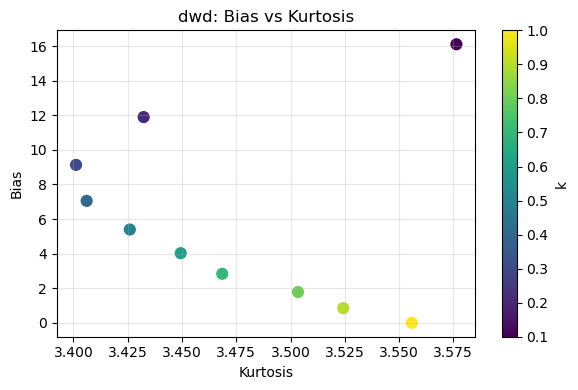

In [28]:
bias_all = []
kurt_all = []
k_all = []

for k in k_list:
	res = results["uniform"][k]

	bias_all.append(res["bias"])
	kurt_all.append(res["kurt"])
	k_all.append(k)

plt.figure(figsize=(6, 4))
sc = plt.scatter(kurt_all, bias_all, c=k_all, cmap="viridis", s=60)

plt.colorbar(sc, label="k")
plt.xlabel("Kurtosis")
plt.ylabel("Bias")
plt.title(f"{distr}: Bias vs Kurtosis")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 2nd stage

##### Model 1 - online correction

In [43]:
def run_simulation_path_corrected(
    rng,
    distr,
    correction_models,
    k,
    max_steps=100,
    min_dist=1,
    max_dist=50,
    sd=None
):
    beta0, beta1, beta2 = correction_models[distr]

    dif_X = np.empty(max_steps, dtype=float)

    running_mean_raw = np.empty(max_steps, dtype=float)
    running_mean_corr = np.full(max_steps, np.nan, dtype=float)

    running_skew = np.full(max_steps, np.nan, dtype=float)
    running_kurt = np.full(max_steps, np.nan, dtype=float)
    running_bias = np.full(max_steps, np.nan, dtype=float)

    # ==============================
    # Data
    # ==============================

    for i in range(max_steps):

        if distr == "uniform":

            rA = rng.uniform(
                min_dist,
                max_dist
            )

            rB = rng.uniform(
                min_dist,
                min_dist + k * (max_dist - min_dist)
            )

        elif distr == "dwd":

            if sd is None:
                raise ValueError(
                    "For distr='dwd', you must provide sd."
                )

            rA = abs(
                rng.normal(
                    0,
                    sd
                )
            ) + 1

            rB = abs(
                rng.normal(
                    0,
                    k * sd
                )
            ) + 1

        else:
            raise ValueError(
                "distr must be one of: 'uniform', 'dwd'."
            )

        dif_X[i] = (
            20 * np.log10(rA / rB)
        )

    # ==============================
    # Online Correction
    # ==============================

    for i in range(max_steps):

        current_data = dif_X[:i + 1]

        n = len(current_data)

        mean_value = np.mean(current_data)

        running_mean_raw[i] = mean_value

        if n >= 4:

            centered = (
                current_data - mean_value
            )


            variance = np.mean(
                centered**2
            )

            std_value = np.sqrt(variance)

            if std_value > 0:

                
                skew_value = (
                    np.mean(centered**3)
                    / std_value**3
                )

            
                kurt_value = (
                    np.mean(centered**4)
                    / std_value**4
                )

                
                bias_hat = (
                    beta0
                    + beta1 * skew_value
                    + beta2 * kurt_value
                )

            
                running_skew[i] = skew_value
                running_kurt[i] = kurt_value
                running_bias[i] = bias_hat

                
                running_mean_corr[i] = (
                    mean_value - bias_hat
                )

    return {
        "dif_X": dif_X,

        "running_mean_raw": running_mean_raw,
        "running_mean_corr": running_mean_corr,

        "running_skew": running_skew,
        "running_kurt": running_kurt,
        "running_bias": running_bias
    }

In [44]:
R = 100
max_steps = 500

k = 1.0

rng = np.random.default_rng(seed=123)

rms_raw = np.empty(
    (R, max_steps),
    dtype=float
)

rms_corr = np.empty(
    (R, max_steps),
    dtype=float
)

for i in range(R):

    sim = run_simulation_path_corrected(
        rng=rng,
        distr="dwd",
        correction_models=correction_models_1,
        k=k,
        max_steps=max_steps,
        min_dist=1,
        max_dist=50,
        sd=30
    )

    rms_raw[i] = (
        sim["running_mean_raw"]
    )

    rms_corr[i] = (
        sim["running_mean_corr"]
    )

In [45]:
raw_mean = np.mean(
    rms_raw,
    axis=0
)

raw_std = np.std(
    rms_raw,
    axis=0,
    ddof=1
)


corr_mean = np.nanmean(
    rms_corr,
    axis=0
)

corr_std = np.nanstd(
    rms_corr,
    axis=0,
    ddof=1
)

x = np.arange(
    1,
    max_steps + 1
)

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4032823931.py:13: RuntimeWarning: Mean of empty slice
  corr_mean = np.nanmean(


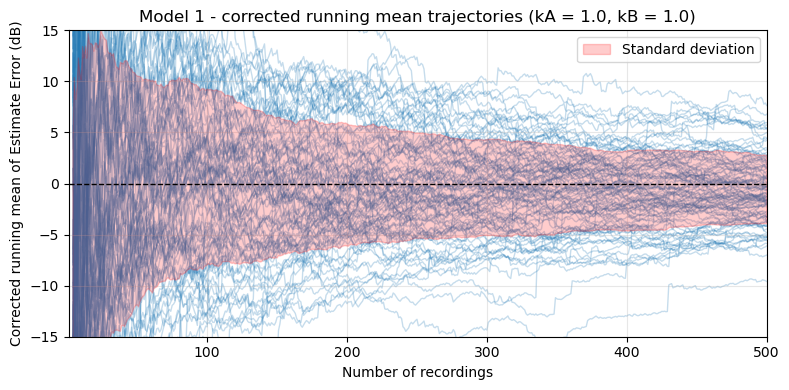

In [46]:
fig, ax = plt.subplots(figsize=(8, 4))

# All corrected runs
for i in range(R):

    ax.plot(
        x,
        rms_corr[i],
        alpha=0.25,
        linewidth=1.0,
        color="tab:blue",
        zorder=1
    )

# ± SD
ax.fill_between(
    x,
    corr_mean - corr_std,
    corr_mean + corr_std,
    color="red",
    alpha=0.20,
    label="Standard deviation",
    zorder=2
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="black",
    zorder=4
)

ax.set_xlabel(
    "Number of recordings"
)

ax.set_ylabel(
    "Corrected running mean of Estimate Error (dB)"
)

ax.set_title(
    f"Model 1 - corrected running mean trajectories (kA = 1.0, kB = {k})"
)

ax.set_xlim(
    1,
    max_steps
)

ax.set_ylim(
    -15,
    15
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### **Scenario 3)**

#### 3-species network (Regression + Network)

##### 1) Large Sample Generation

In [47]:
N = 1000000
rng = np.random.default_rng(seed=123)

min_dist = 1
max_dist = 50

k_list = [1, 0.9, 0.8, 0.7, 0.6 , 0.5, 0.4, 0.3, 0.2, 0.1]

sd_A = 30  

distr_list = ["uniform", "dwd"]

results = {distr: {} for distr in distr_list}


for distr in distr_list:

	# Draw rA once for metrics (per distribution)
	if distr == "uniform":
		rA = rng.uniform(min_dist, max_dist, size=N)

	elif distr == "dwd":
		rA = np.abs(rng.normal(loc=0, scale=sd_A, size=N)) + 1

	else:
		raise ValueError("Invalid distr.")

	for k in k_list:

		
		if distr == "uniform":
			
			rB = rng.uniform(min_dist, min_dist + k * (max_dist - min_dist), size=N)

		elif distr == "dwd":
			
			sd_B = k * sd_A
			rB = np.abs(rng.normal(loc=0, scale=sd_B, size=N)) + 1

		
		dif_X = 20 * np.log10(rA / rB)


		### Metrics

		# Mean
		mean_dif = mean_f(dif_X)

		# Standard deviation
		sd_dif = std_dev_f(dif_X)

		# Skewness
		skew =skewness_f(dif_X)

		# Kurtosis
		kurt = kurtosis_f(dif_X)

		results[distr][k] = {
			"rA_mean": rA.mean(),
			"rB_mean": rB.mean(),
			"mean": mean_dif,
			"sd": sd_dif,
			"skew": skew,
			"kurt": kurt,
			"dif_X": dif_X
		}

##### 2) Regression Model


Distribution: uniform
Summary (before correction):

k = 1.0  bias = -0.0030 dB  skew = 0.0041  kurtosis = 3.5559
k = 0.9  bias = 0.8440 dB  skew = -0.0272  kurtosis = 3.5243
k = 0.8  bias = 1.7754 dB  skew = -0.0587  kurtosis = 3.5034
k = 0.7  bias = 2.8322 dB  skew = -0.0907  kurtosis = 3.4685
k = 0.6  bias = 4.0237 dB  skew = -0.1366  kurtosis = 3.4494
k = 0.5  bias = 5.3912 dB  skew = -0.1906  kurtosis = 3.4260
k = 0.4  bias = 7.0503 dB  skew = -0.2628  kurtosis = 3.4061
k = 0.3  bias = 9.1329 dB  skew = -0.3525  kurtosis = 3.4012
k = 0.2  bias = 11.8984 dB  skew = -0.4907  kurtosis = 3.4323
k = 0.1  bias = 16.1104 dB  skew = -0.7366  kurtosis = 3.5764

Fitted correction model:

bias ≈ 30.203199 + -22.017905 * skew + -8.477800 * kurtosis

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0030 dB  bias_corr = -0.0330 dB  corrected_mean = 0.0300 dB
k = 0.9  raw_mean = 0.8440 dB  bias_corr = 0.9230 dB  corrected_mean = -0.0790 dB
k = 0.8  raw_mean = 1.7754 dB  bias_corr = 1.7

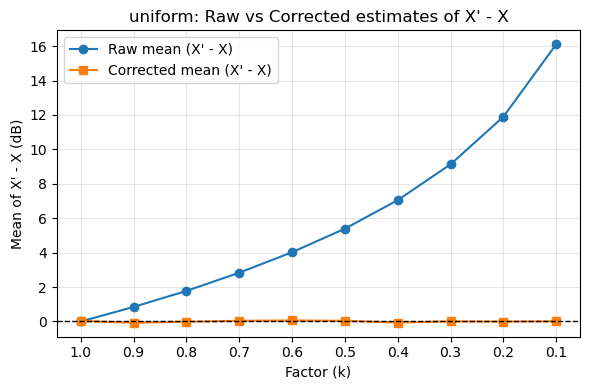


Distribution: dwd
Summary (before correction):

k = 1.0  bias = -0.0019 dB  skew = 0.0006  kurtosis = 3.0987
k = 0.9  bias = 0.8187 dB  skew = -0.0188  kurtosis = 3.0822
k = 0.8  bias = 1.7309 dB  skew = -0.0470  kurtosis = 3.0606
k = 0.7  bias = 2.7717 dB  skew = -0.0705  kurtosis = 3.0389
k = 0.6  bias = 3.9232 dB  skew = -0.1058  kurtosis = 3.0265
k = 0.5  bias = 5.2827 dB  skew = -0.1435  kurtosis = 3.0052
k = 0.4  bias = 6.9095 dB  skew = -0.1917  kurtosis = 2.9960
k = 0.3  bias = 8.9300 dB  skew = -0.2566  kurtosis = 2.9897
k = 0.2  bias = 11.6098 dB  skew = -0.3473  kurtosis = 2.9991
k = 0.1  bias = 15.6614 dB  skew = -0.4960  kurtosis = 3.0551

Fitted correction model:

bias ≈ 29.000976 + -30.718421 * skew + -9.352828 * kurtosis

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0019 dB  bias_corr = 0.0000 dB  corrected_mean = -0.0019 dB
k = 0.9  raw_mean = 0.8187 dB  bias_corr = 0.7527 dB  corrected_mean = 0.0660 dB
k = 0.8  raw_mean = 1.7309 dB  bias_corr = 1.8184 d

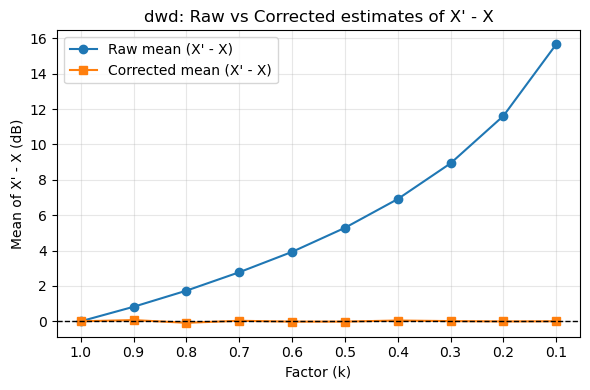

In [48]:
regression_model = {}  # will contain (beta0, beta1, beta2) for each distr

for distr in distr_list:

	bias_list = []
	skew_list = []
	kurt_list = []

	for k in k_list:
		res = results[distr][k]

		bias = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		results[distr][k]["bias"] = bias

		bias_list.append(bias)
		skew_list.append(skew)
		kurt_list.append(kurt)

	### BEFORE correction summary

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Summary (before correction):\n")

	for k in k_list:
		res = results[distr][k]
		print(
			f"k = {k:.1f}  "
			f"bias = {res['bias']:.4f} dB  "
			f"skew = {res['skew']:.4f}  "
			f"kurtosis = {res['kurt']:.4f}"
		)

	### Multiple linear regression:
	### bias ≈ b0 + b1*skew + b2*kurt

	skew_arr = np.array(skew_list)
	kurt_arr = np.array(kurt_list)

	X_mat = np.column_stack([
		np.ones(len(k_list)),   # intercept
		skew_arr,               # skew
		kurt_arr                # kurt
	])

	y_vec = np.array(bias_list)

	beta, residuals, rank, s = np.linalg.lstsq(
		X_mat,
		y_vec,
		rcond=None
	)

	beta0, beta1, beta2 = beta

	regression_model[distr] = (
		beta0,
		beta1,
		beta2
	)

	print("\nFitted correction model:\n")
	print(
		f"bias ≈ {beta0:.6f} "
		f"+ {beta1:.6f} * skew "
		f"+ {beta2:.6f} * kurtosis\n"
	)

	### AFTER correction summary

	print("Raw vs Corrected means for each k:\n")

	for k in k_list:
		res = results[distr][k]

		mean_raw = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		bias_corr = (
			beta0
			+ beta1 * skew
			+ beta2 * kurt
		)

		mean_corr = (
			mean_raw
			- bias_corr
		)

		results[distr][k]["bias_corr"] = bias_corr
		results[distr][k]["mean_corr"] = mean_corr

		print(
			f"k = {k:.1f}  "
			f"raw_mean = {mean_raw:.4f} dB  "
			f"bias_corr = {bias_corr:.4f} dB  "
			f"corrected_mean = {mean_corr:.4f} dB"
		)

	### Plot raw vs corrected

	raw_bias = [
		results[distr][k]["mean"]
		for k in k_list
	]

	corr_bias = [
		results[distr][k]["mean_corr"]
		for k in k_list
	]

	plt.figure(figsize=(6, 4))

	plt.plot(
		k_list,
		raw_bias,
		marker="o",
		label="Raw mean (X' - X)"
	)

	plt.plot(
		k_list,
		corr_bias,
		marker="s",
		label="Corrected mean (X' - X)"
	)

	plt.axhline(
		0,
		linestyle="--",
		linewidth=1,
		color="black"
	)

	plt.gca().invert_xaxis()
	plt.xticks(k_list)

	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")

	plt.title(
		f"{distr}: Raw vs Corrected estimates of X' - X"
	)

	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

##### 3) Initial simulation

In [49]:
import numpy as np
import matplotlib.pyplot as plt


def initial_sim_3_sp(
    max_steps=500,
    sd=30,
    k_A=1.0,
    k_B=0.5,
    k_C=0.5,
    run_index=0
):

    rng_AB = np.random.default_rng(123 + run_index)
    rA_AB = np.abs(rng_AB.normal(0, sd * k_A, size=max_steps)) + 1
    rB_AB = np.abs(rng_AB.normal(0, sd * k_B, size=max_steps)) + 1

    rng_AC = np.random.default_rng(124 + run_index)
    rA_AC = np.abs(rng_AC.normal(0, sd * k_A, size=max_steps)) + 1
    rC_AC = np.abs(rng_AC.normal(0, sd * k_C, size=max_steps)) + 1

    rng_BC = np.random.default_rng(125 + run_index)
    rB_BC = np.abs(rng_BC.normal(0, sd * k_B, size=max_steps)) + 1
    rC_BC = np.abs(rng_BC.normal(0, sd * k_C, size=max_steps)) + 1

    dif_X_AB = 20 * np.log10(rA_AB / rB_AB)
    dif_X_AC = 20 * np.log10(rA_AC / rC_AC)
    dif_X_BC = 20 * np.log10(rB_BC / rC_BC)

    running_mean_AB = (
        np.cumsum(dif_X_AB)
        / np.arange(1, max_steps + 1)
    )

    running_mean_AC = (
        np.cumsum(dif_X_AC)
        / np.arange(1, max_steps + 1)
    )

    running_mean_BC = (
        np.cumsum(dif_X_BC)
        / np.arange(1, max_steps + 1)
    )

    return {
        "dif_X_AB": dif_X_AB,
        "dif_X_AC": dif_X_AC,
        "dif_X_BC": dif_X_BC,
        "running_mean_AB": running_mean_AB,
        "running_mean_AC": running_mean_AC,
        "running_mean_BC": running_mean_BC,
    }

In [50]:
R = 100
max_steps = 500

runs_AB = np.empty((R, max_steps))
runs_AC = np.empty((R, max_steps))
runs_BC = np.empty((R, max_steps))

for i in range(R):

    sim = initial_sim_3_sp(
        max_steps=max_steps,
        sd=30,
        k_A=1.0,
        k_B=0.5,
        k_C=0.5,
        run_index=i
    )

    runs_AB[i] = sim["running_mean_AB"]
    runs_AC[i] = sim["running_mean_AC"]
    runs_BC[i] = sim["running_mean_BC"]

In [51]:
mean_AB = runs_AB.mean(axis=0)
mean_AC = runs_AC.mean(axis=0)
mean_BC = runs_BC.mean(axis=0)
std_AB = runs_AB.std(axis=0)
std_AC = runs_AC.std(axis=0)
std_BC = runs_BC.std(axis=0)

x = np.arange(1, max_steps + 1)

##### 4) Initial plot

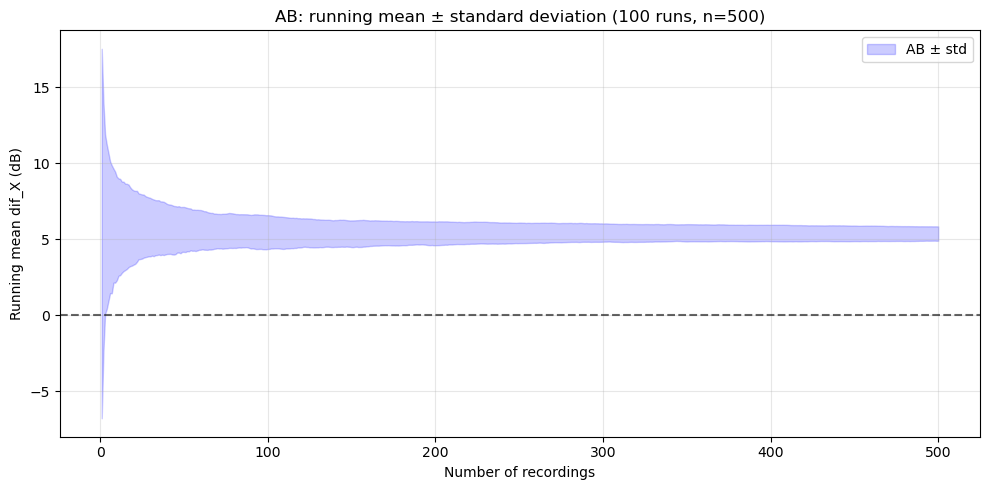

In [52]:
# ==============================
# Plot
# ==============================
fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(
    x,
    mean_AB - std_AB,
    mean_AB + std_AB,
    color="blue",
    alpha=0.20,
    label="AB ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: running mean ± standard deviation "
    f"({R} runs, n={max_steps})"
)

ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()



plt.tight_layout()
plt.show()

##### 5) Regression Correction

In [62]:
def online_update_moments(n, mean, M2, M3, M4, x):

    n_anterior = n
    n = n + 1

    delta = x - mean
    delta_n = delta / n
    delta_n2 = delta_n ** 2

    term1 = delta * delta_n * n_anterior

    M4_novo = (
        M4
        + term1 * delta_n2 * (n**2 - 3*n + 3)
        + 6 * delta_n2 * M2
        - 4 * delta_n * M3
    )

    M3_novo = (
        M3
        + term1 * delta_n * (n - 2)
        - 3 * delta_n * M2
    )

    M2_novo = M2 + term1
    mean_nova = mean + delta_n

    return (
        n,
        mean_nova,
        M2_novo,
        M3_novo,
        M4_novo
    )

In [63]:
def correct_pair_from_runs(
    runs,
    pair,
    correction_models,
    distr="dwd"
):
    pair = pair.upper()

    runs = np.asarray(runs, dtype=float)

    if runs.ndim != 2:
        raise ValueError(
            "runs' matrix should have dimension (R, max_steps)."
        )

    R, max_steps = runs.shape

    if R == 0 or max_steps == 0:
        raise ValueError("runs cannot be empty")

    if distr not in correction_models:
        raise KeyError(
            f"No existent model {distr!r}."
        )

    coefficients = np.asarray(
        correction_models[distr],
        dtype=float
    )

    if coefficients.size != 3:
        raise ValueError(
            "Correction model must have exactly 3 coefficients"
        )

    beta0, beta1, beta2 = coefficients

    running_mean_raw = runs.copy()

    # ==============================
    # Rebuild individual dif_X
    # ==============================

    dif_X_runs = np.empty(
        (R, max_steps),
        dtype=float
    )

    dif_X_runs[:, 0] = running_mean_raw[:, 0]


    for i in range(1, max_steps):

        n = i + 1

        dif_X_runs[:, i] = (
            n * running_mean_raw[:, i]
            - (n - 1) * running_mean_raw[:, i - 1]
        )

    # ==============================
    # Output
    # ==============================

    running_skewness = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    running_kurtosis = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    running_bias = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    running_mean_corr = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    # ==============================
    # Each run
    # ==============================

    for run_index in range(R):

        dif_X = dif_X_runs[run_index]


        n = 0
        mean = 0.0
        M2 = 0.0
        M3 = 0.0
        M4 = 0.0

        for i, x_value in enumerate(dif_X):

            (
                n,
                mean,
                M2,
                M3,
                M4
            ) = online_update_moments(
                n,
                mean,
                M2,
                M3,
                M4,
                x_value
            )

        
            if n >= 4 and M2 > 0:

                momento_2 = M2 / n
                momento_3 = M3 / n
                momento_4 = M4 / n

                
                skew_value = (
                    momento_3
                    / momento_2**1.5
                )

                
                kurt_value = (
                    momento_4
                    / momento_2**2
                )

                
                bias_hat = (
                    beta0
                    + beta1 * skew_value
                    + beta2 * kurt_value
                )

                running_skewness[run_index, i] = (
                    skew_value
                )

                running_kurtosis[run_index, i] = (
                    kurt_value
                )

                running_bias[run_index, i] = (
                    bias_hat
                )

                running_mean_corr[run_index, i] = (
                    running_mean_raw[run_index, i]
                    - bias_hat
                )

    return {
        "pair": pair,
        "R": R,
        "max_steps": max_steps,

        "dif_X_reconstructed": dif_X_runs,

        "running_mean_raw": running_mean_raw,
        "running_skewness": running_skewness,
        "running_kurtosis": running_kurtosis,
        "running_bias": running_bias,
        "running_mean_corr": running_mean_corr
    }

In [64]:
result_AB = correct_pair_from_runs(
    runs=runs_AB,
    pair="AB",
    correction_models=regression_model,
    distr="dwd"
)

result_AC = correct_pair_from_runs(
    runs=runs_AC,
    pair="AC",
    correction_models=regression_model,
    distr="dwd"
)

result_BC = correct_pair_from_runs(
    runs=runs_BC,
    pair="BC",
    correction_models=regression_model,
    distr="dwd"
)

In [65]:
# ==============================
# Metrics for 100 runs
# ==============================

raw_AB = result_AB["running_mean_raw"]
corr_AB = result_AB["running_mean_corr"]

mean_AB = np.mean(raw_AB, axis=0)
std_AB = np.std(raw_AB, axis=0)

corr_mean_AB = np.nanmean(corr_AB, axis=0)
corr_std_AB = np.nanstd(corr_AB, axis=0)


raw_AC = result_AC["running_mean_raw"]
corr_AC = result_AC["running_mean_corr"]

mean_AC = np.mean(raw_AC, axis=0)
std_AC = np.std(raw_AC, axis=0)

corr_mean_AC = np.nanmean(corr_AC, axis=0)
corr_std_AC = np.nanstd(corr_AC, axis=0)


raw_BC = result_BC["running_mean_raw"]
corr_BC = result_BC["running_mean_corr"]

mean_BC = np.mean(raw_BC, axis=0)
std_BC = np.std(raw_BC, axis=0)

corr_mean_BC = np.nanmean(corr_BC, axis=0)
corr_std_BC = np.nanstd(corr_BC, axis=0)

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\1552509589.py:11: RuntimeWarning: Mean of empty slice
  corr_mean_AB = np.nanmean(corr_AB, axis=0)
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\1552509589.py:21: RuntimeWarning: Mean of empty slice
  corr_mean_AC = np.nanmean(corr_AC, axis=0)
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\1552509589.py:31: RuntimeWarning: Mean of empty slice
  corr_mean_BC = np.nanmean(corr_BC, axis=0)


##### 6) Corrected plot

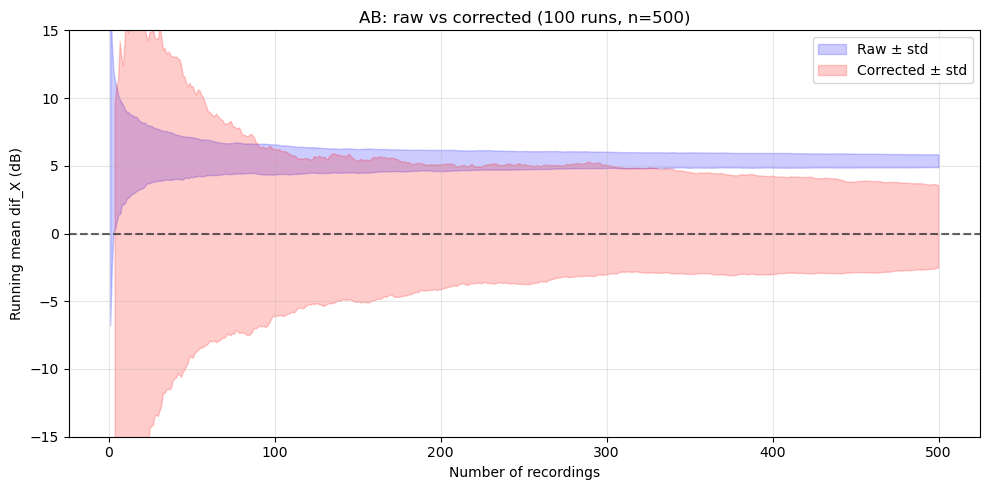

In [66]:
# ==============================
# Plot
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Raw
ax.fill_between(
    x,
    mean_AB - std_AB,
    mean_AB + std_AB,
    color="blue",
    alpha=0.20,
    label="Raw ± std"
)

# Regression Corrected
ax.fill_between(
    x,
    corr_mean_AB - corr_std_AB,
    corr_mean_AB + corr_std_AB,
    color="red",
    alpha=0.20,
    label="Corrected ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: raw vs corrected "
    f"({R} runs, n={max_steps})"
)

ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.ylim(-15, 15)

plt.tight_layout()
plt.show()

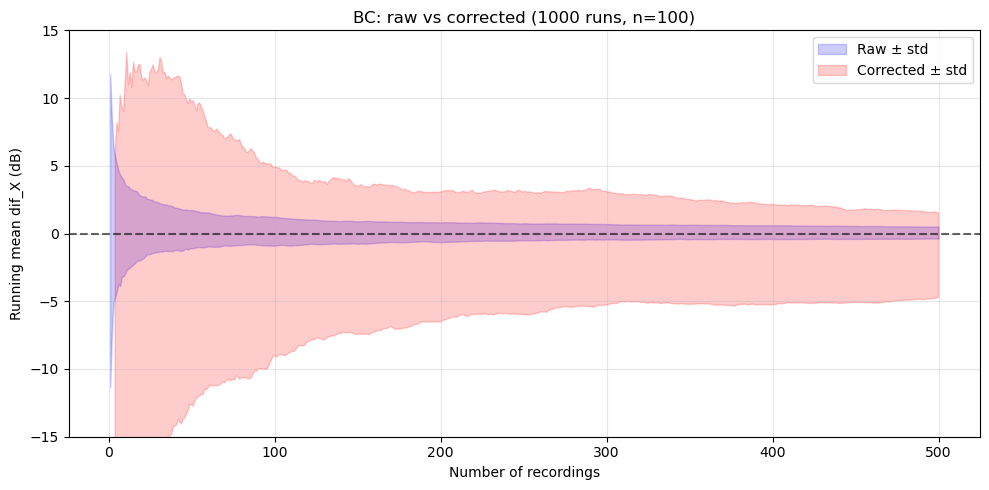

In [67]:
# ==============================
# Plot
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Raw
ax.fill_between(
    x,
    mean_BC - std_BC,
    mean_BC + std_BC,
    color="blue",
    alpha=0.20,
    label="Raw ± std"
)

# Regression Corrected
ax.fill_between(
    x,
    corr_mean_BC - corr_std_BC,
    corr_mean_BC + corr_std_BC,
    color="red",
    alpha=0.20,
    label="Corrected ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: raw vs corrected "
    f"({R} runs, n={max_steps})"
)

ax.set_title("BC: raw vs corrected (1000 runs, n=100)")
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.ylim(-15, 15)

plt.tight_layout()
plt.show()

##### 7) Simple Network Correction

In [68]:
# ==============================
# Closure error for ABC
# 3 species
# ==============================

triangle_error_ABC_3 = (
    corr_AB
    + corr_BC
    - corr_AC
)


# ==============================
# Error distribution
# 3 species
# ==============================

distributed_error_ABC_3 = (
    triangle_error_ABC_3 / 3
)


# ==============================
# Double correction (regression + network)
# 3 species
# ==============================

corr_net_AB_3 = (
    corr_AB
    - distributed_error_ABC_3
)

corr_net_AC_3 = (
    corr_AC
    + distributed_error_ABC_3
)

corr_net_BC_3 = (
    corr_BC
    - distributed_error_ABC_3
)


In [69]:
# ==============================
# Metrics for 100 runs
# 3 species
# ==============================

corr_net_mean_AB_3 = np.nanmean(
    corr_net_AB_3,
    axis=0
)

corr_net_std_AB_3 = np.nanstd(
    corr_net_AB_3,
    axis=0
)


corr_net_mean_AC_3 = np.nanmean(
    corr_net_AC_3,
    axis=0
)

corr_net_std_AC_3 = np.nanstd(
    corr_net_AC_3,
    axis=0
)


corr_net_mean_BC_3 = np.nanmean(
    corr_net_BC_3,
    axis=0
)

corr_net_std_BC_3 = np.nanstd(
    corr_net_BC_3,
    axis=0
)

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4279672946.py:6: RuntimeWarning: Mean of empty slice
  corr_net_mean_AB_3 = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4279672946.py:17: RuntimeWarning: Mean of empty slice
  corr_net_mean_AC_3 = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4279672946.py:28: RuntimeWarning: Mean of empty slice
  corr_net_mean_BC_3 = np.nanmean(


##### 8) Final Corrected Plot

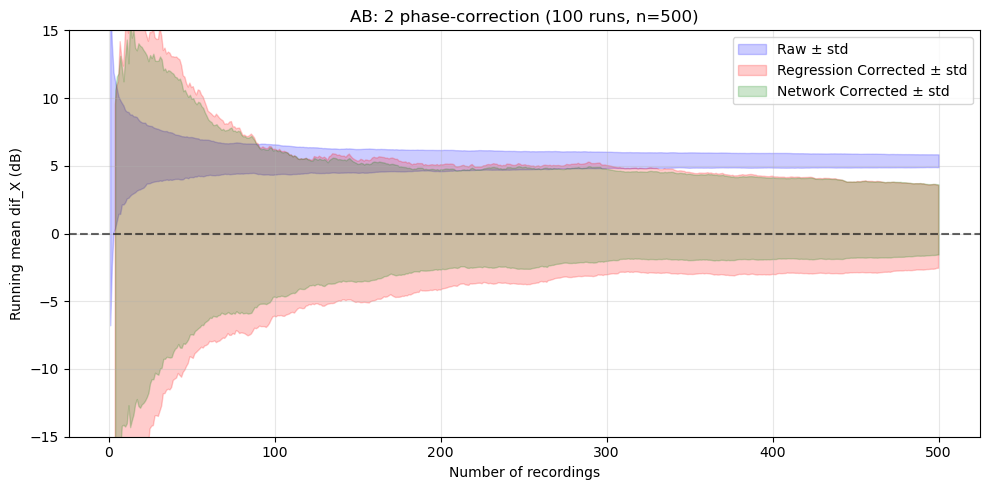

In [70]:
# ==============================
# Plot
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Raw
ax.fill_between(
    x,
    mean_AB - std_AB,
    mean_AB + std_AB,
    color="blue",
    alpha=0.20,
    label="Raw ± std"
)

# Regression Corrected
ax.fill_between(
    x,
    corr_mean_AB - corr_std_AB,
    corr_mean_AB + corr_std_AB,
    color="red",
    alpha=0.20,
    label="Regression Corrected ± std"
)

# Regression + Network Corrected
ax.fill_between(
    x,
    corr_net_mean_AB_3 - corr_net_std_AB_3,
    corr_net_mean_AB_3 + corr_net_std_AB_3,
    color="green",
    alpha=0.20,
    label="Network Corrected ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: 2 phase-correction "
    f"({R} runs, n={max_steps})"
)

ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.ylim(-15, 15)

plt.tight_layout()
plt.show()

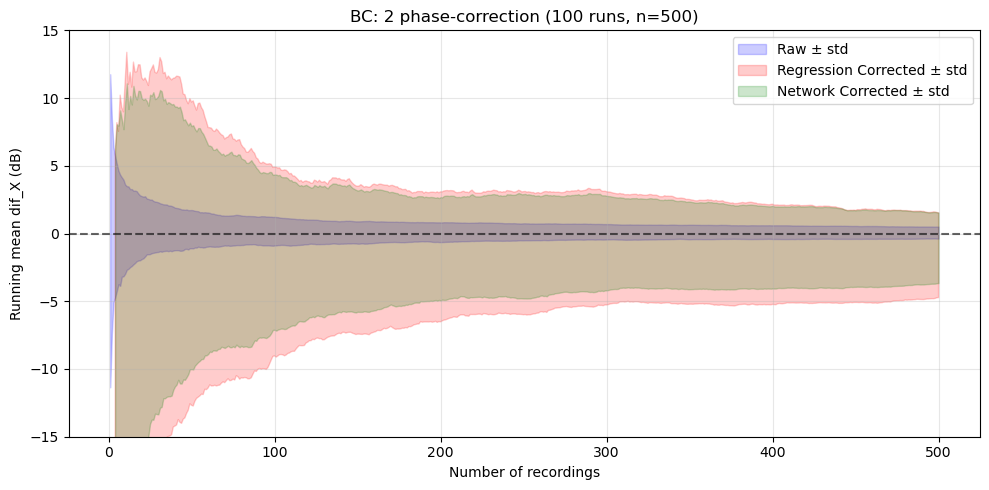

In [71]:
# ==============================
# Plot
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Raw
ax.fill_between(
    x,
    mean_BC - std_BC,
    mean_BC + std_BC,
    color="blue",
    alpha=0.20,
    label="Raw ± std"
)

# Regression Corrected
ax.fill_between(
    x,
    corr_mean_BC - corr_std_BC,
    corr_mean_BC + corr_std_BC,
    color="red",
    alpha=0.20,
    label="Regression Corrected ± std"
)

# Regression + Network Corrected
ax.fill_between(
    x,
    corr_net_mean_BC_3 - corr_net_std_BC_3,
    corr_net_mean_BC_3 + corr_net_std_BC_3,
    color="green",
    alpha=0.20,
    label="Network Corrected ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"BC: 2 phase-correction "
    f"({R} runs, n={max_steps})"
)

ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.ylim(-15, 15)

plt.tight_layout()
plt.show()

#### 10-species network (Regression + Network)

##### 1) Large Sample Generation

In [72]:
N = 1000000
rng = np.random.default_rng(seed=123)

min_dist = 1
max_dist = 50

k_list = [1, 0.9, 0.8, 0.7, 0.6 , 0.5, 0.4, 0.3, 0.2, 0.1]

sd_A = 30  

distr_list = ["uniform", "dwd"]

results = {distr: {} for distr in distr_list}  


for distr in distr_list:


	if distr == "uniform":
		rA = rng.uniform(min_dist, max_dist, size=N)

	elif distr == "dwd":
		rA = np.abs(rng.normal(loc=0, scale=sd_A, size=N)) + 1

	else:
		raise ValueError("Invalid distr.")

	for k in k_list:

	
		if distr == "uniform":
			
			rB = rng.uniform(min_dist, min_dist + k * (max_dist - min_dist), size=N)

		elif distr == "dwd":
			
			sd_B = k * sd_A
			rB = np.abs(rng.normal(loc=0, scale=sd_B, size=N)) + 1

		
		dif_X = 20 * np.log10(rA / rB)


		### Metrics

		# Mean
		mean_dif = mean_f(dif_X)

		# Standard deviation
		sd_dif = std_dev_f(dif_X)

		# Skewness
		skew =skewness_f(dif_X)

		# Kurtosis
		kurt = kurtosis_f(dif_X)

		results[distr][k] = {
			"rA_mean": rA.mean(),
			"rB_mean": rB.mean(),
			"mean": mean_dif,
			"sd": sd_dif,
			"skew": skew,
			"kurt": kurt,
			"dif_X": dif_X
		}

##### 2) Regression Model


Distribution: uniform
Summary (before correction):

k = 1.0  bias = -0.0030 dB  skew = 0.0041  kurtosis = 3.5559
k = 0.9  bias = 0.8440 dB  skew = -0.0272  kurtosis = 3.5243
k = 0.8  bias = 1.7754 dB  skew = -0.0587  kurtosis = 3.5034
k = 0.7  bias = 2.8322 dB  skew = -0.0907  kurtosis = 3.4685
k = 0.6  bias = 4.0237 dB  skew = -0.1366  kurtosis = 3.4494
k = 0.5  bias = 5.3912 dB  skew = -0.1906  kurtosis = 3.4260
k = 0.4  bias = 7.0503 dB  skew = -0.2628  kurtosis = 3.4061
k = 0.3  bias = 9.1329 dB  skew = -0.3525  kurtosis = 3.4012
k = 0.2  bias = 11.8984 dB  skew = -0.4907  kurtosis = 3.4323
k = 0.1  bias = 16.1104 dB  skew = -0.7366  kurtosis = 3.5764

Fitted correction model:

bias ≈ 30.203199 + -22.017905 * skew + -8.477800 * kurtosis

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0030 dB  bias_corr = -0.0330 dB  corrected_mean = 0.0300 dB
k = 0.9  raw_mean = 0.8440 dB  bias_corr = 0.9230 dB  corrected_mean = -0.0790 dB
k = 0.8  raw_mean = 1.7754 dB  bias_corr = 1.7

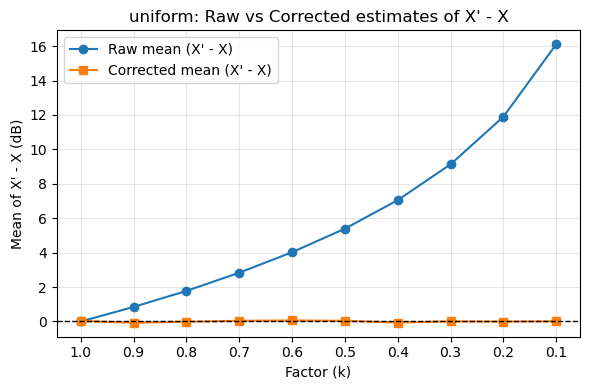


Distribution: dwd
Summary (before correction):

k = 1.0  bias = -0.0019 dB  skew = 0.0006  kurtosis = 3.0987
k = 0.9  bias = 0.8187 dB  skew = -0.0188  kurtosis = 3.0822
k = 0.8  bias = 1.7309 dB  skew = -0.0470  kurtosis = 3.0606
k = 0.7  bias = 2.7717 dB  skew = -0.0705  kurtosis = 3.0389
k = 0.6  bias = 3.9232 dB  skew = -0.1058  kurtosis = 3.0265
k = 0.5  bias = 5.2827 dB  skew = -0.1435  kurtosis = 3.0052
k = 0.4  bias = 6.9095 dB  skew = -0.1917  kurtosis = 2.9960
k = 0.3  bias = 8.9300 dB  skew = -0.2566  kurtosis = 2.9897
k = 0.2  bias = 11.6098 dB  skew = -0.3473  kurtosis = 2.9991
k = 0.1  bias = 15.6614 dB  skew = -0.4960  kurtosis = 3.0551

Fitted correction model:

bias ≈ 29.000976 + -30.718421 * skew + -9.352828 * kurtosis

Raw vs Corrected means for each k:

k = 1.0  raw_mean = -0.0019 dB  bias_corr = 0.0000 dB  corrected_mean = -0.0019 dB
k = 0.9  raw_mean = 0.8187 dB  bias_corr = 0.7527 dB  corrected_mean = 0.0660 dB
k = 0.8  raw_mean = 1.7309 dB  bias_corr = 1.8184 d

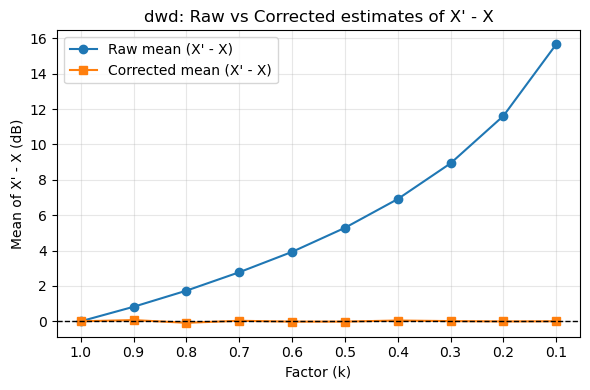

In [73]:
regression_model = {}  # will contain (beta0, beta1, beta2) for each distr

for distr in distr_list:

	bias_list = []
	skew_list = []
	kurt_list = []

	for k in k_list:
		res = results[distr][k]

		bias = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		results[distr][k]["bias"] = bias

		bias_list.append(bias)
		skew_list.append(skew)
		kurt_list.append(kurt)

	### BEFORE correction summary

	print("\n" + "=" * 60)
	print(f"Distribution: {distr}")
	print("Summary (before correction):\n")

	for k in k_list:
		res = results[distr][k]

		print(
			f"k = {k:.1f}  "
			f"bias = {res['bias']:.4f} dB  "
			f"skew = {res['skew']:.4f}  "
			f"kurtosis = {res['kurt']:.4f}"
		)

	### Multiple linear regression:
	### bias ≈ b0 + b1*skew + b2*kurt

	skew_arr = np.array(skew_list)
	kurt_arr = np.array(kurt_list)

	X_mat = np.column_stack([
		np.ones(len(k_list)),   # intercept
		skew_arr,               # skew
		kurt_arr                # kurt
	])

	y_vec = np.array(bias_list)

	beta, residuals, rank, s = np.linalg.lstsq(
		X_mat,
		y_vec,
		rcond=None
	)

	beta0, beta1, beta2 = beta

	regression_model[distr] = (
		beta0,
		beta1,
		beta2
	)

	print("\nFitted correction model:\n")

	print(
		f"bias ≈ {beta0:.6f} "
		f"+ {beta1:.6f} * skew "
		f"+ {beta2:.6f} * kurtosis\n"
	)

	### AFTER correction summary

	print("Raw vs Corrected means for each k:\n")

	for k in k_list:

		res = results[distr][k]

		mean_raw = res["mean"]
		skew = res["skew"]
		kurt = res["kurt"]

		bias_corr = (
			beta0
			+ beta1 * skew
			+ beta2 * kurt
		)

		mean_corr = (
			mean_raw
			- bias_corr
		)

		results[distr][k]["bias_corr"] = bias_corr
		results[distr][k]["mean_corr"] = mean_corr

		print(
			f"k = {k:.1f}  "
			f"raw_mean = {mean_raw:.4f} dB  "
			f"bias_corr = {bias_corr:.4f} dB  "
			f"corrected_mean = {mean_corr:.4f} dB"
		)

	### Plot raw vs corrected

	raw_bias = [
		results[distr][k]["mean"]
		for k in k_list
	]

	corr_bias = [
		results[distr][k]["mean_corr"]
		for k in k_list
	]

	plt.figure(figsize=(6, 4))

	plt.plot(
		k_list,
		raw_bias,
		marker="o",
		label="Raw mean (X' - X)"
	)

	plt.plot(
		k_list,
		corr_bias,
		marker="s",
		label="Corrected mean (X' - X)"
	)

	plt.axhline(
		0,
		linestyle="--",
		linewidth=1,
		color="black"
	)

	plt.gca().invert_xaxis()
	plt.xticks(k_list)

	plt.xlabel("Factor (k)")
	plt.ylabel("Mean of X' - X (dB)")

	plt.title(
		f"{distr}: Raw vs Corrected estimates of X' - X"
	)

	plt.grid(alpha=0.3)
	plt.legend()
	plt.tight_layout()
	plt.show()

##### 3) Initial simulation

In [77]:
import numpy as np

species = list("ABCDEFGHIJ")

k_species = {
    "A": 1.0,
    "B": 0.5,
    "C": 0.5,
    "D": 0.7,
    "E": 0.6,
    "F": 0.5,
    "G": 0.4,
    "H": 0.3,
    "I": 0.2,
    "J": 0.1,
}

R = 100
max_steps = 500
sd = 30
base_seed = 123

r_species = {
    sp: np.empty((R, max_steps), dtype=float)
    for sp in species
}

for run_index in range(R):

    for species_index, sp in enumerate(species):

        rng = np.random.default_rng(
            [base_seed, run_index, species_index]
        )

        r_species[sp][run_index] = (
            np.abs(
                rng.normal(
                    0,
                    sd * k_species[sp],
                    size=max_steps
                )
            )
            + 1
        )

In [78]:
# For AB and BC
needed_pairs = [
    "AB",
    "AC", "AD", "AE", "AF", "AG", "AH", "AI", "AJ",
    "BC", "BD", "BE", "BF", "BG", "BH", "BI", "BJ",
    "CD", "CE", "CF", "CG", "CH", "CI", "CJ",
]

dif_X = {}
running_mean = {}

n_recordings = np.arange(1, max_steps + 1)

for pair in needed_pairs:

    sp1 = pair[0]
    sp2 = pair[1]

    dif_X[pair] = (
        20
        * np.log10(
            r_species[sp1]
            / r_species[sp2]
        )
    )

    running_mean[pair] = (
        np.cumsum(
            dif_X[pair],
            axis=1
        )
        / n_recordings
    )

In [79]:
# ==============================
# Metrics for AB between runs
# ==============================

raw_AB = running_mean["AB"]

mean_AB = np.mean(
    raw_AB,
    axis=0
)

std_AB = np.std(
    raw_AB,
    axis=0
)

x = np.arange(1, max_steps + 1)

##### 4) Initial Plot

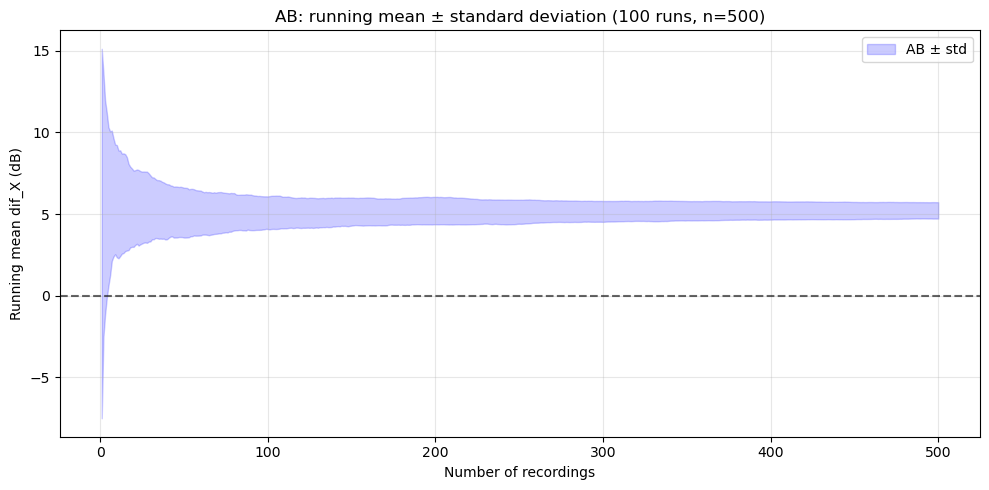

In [80]:
# ==============================
# Plot
# ==============================

fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(
    x,
    mean_AB - std_AB,
    mean_AB + std_AB,
    color="blue",
    alpha=0.20,
    label="AB ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: running mean ± standard deviation "
    f"({R} runs, n={max_steps})"
)

ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

##### 5) Regression Correction

In [88]:
def online_update_moments(n, mean, M2, M3, M4, x):

    n_anterior = n
    n = n + 1

    delta = x - mean
    delta_n = delta / n
    delta_n2 = delta_n ** 2

    term1 = delta * delta_n * n_anterior

    M4_novo = (
        M4
        + term1 * delta_n2 * (n**2 - 3*n + 3)
        + 6 * delta_n2 * M2
        - 4 * delta_n * M3
    )

    M3_novo = (
        M3
        + term1 * delta_n * (n - 2)
        - 3 * delta_n * M2
    )

    M2_novo = M2 + term1
    mean_nova = mean + delta_n

    return (
        n,
        mean_nova,
        M2_novo,
        M3_novo,
        M4_novo
    )

In [89]:
def correct_pair_from_runs(
    runs,
    pair,
    correction_models,
    distr="dwd"
):
    pair = pair.upper()

    runs = np.asarray(runs, dtype=float)

    if runs.ndim != 2:
        raise ValueError(
            "Runs' matrix should have dimension (R, max_steps)."
        )

    R, max_steps = runs.shape

    if R == 0 or max_steps == 0:
        raise ValueError("runs cannot be empty.")

    if distr not in correction_models:
        raise KeyError(
            f"No regression model {distr!r}."
        )

    coefficients = np.asarray(
        correction_models[distr],
        dtype=float
    )

    if coefficients.size != 3:
        raise ValueError(
            "Correction model must have exactly 3 coefficients."
        )

    beta0, beta1, beta2 = coefficients


    running_mean_raw = runs.copy()

    # ==============================
    # Rebuild individual dif_X
    # ==============================

    dif_X_runs = np.empty(
        (R, max_steps),
        dtype=float
    )


    dif_X_runs[:, 0] = running_mean_raw[:, 0]

    
    for i in range(1, max_steps):

        n = i + 1

        dif_X_runs[:, i] = (
            n * running_mean_raw[:, i]
            - (n - 1) * running_mean_raw[:, i - 1]
        )

    # ==============================
    # Output
    # ==============================

    running_skewness = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    running_kurtosis = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    running_bias = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    running_mean_corr = np.full(
        (R, max_steps),
        np.nan,
        dtype=float
    )

    # ==============================
    # Each run
    # ==============================

    for run_index in range(R):

        dif_X = dif_X_runs[run_index]


        n = 0
        mean = 0.0
        M2 = 0.0
        M3 = 0.0
        M4 = 0.0

        for i, x_value in enumerate(dif_X):

            (
                n,
                mean,
                M2,
                M3,
                M4
            ) = online_update_moments(
                n,
                mean,
                M2,
                M3,
                M4,
                x_value
            )

        
            if n >= 4 and M2 > 0:

                momento_2 = M2 / n
                momento_3 = M3 / n
                momento_4 = M4 / n

            
                skew_value = (
                    momento_3
                    / momento_2**1.5
                )

                
                kurt_value = (
                    momento_4
                    / momento_2**2
                )

            
                bias_hat = (
                    beta0
                    + beta1 * skew_value
                    + beta2 * kurt_value
                )

                running_skewness[run_index, i] = (
                    skew_value
                )

                running_kurtosis[run_index, i] = (
                    kurt_value
                )

                running_bias[run_index, i] = (
                    bias_hat
                )

                running_mean_corr[run_index, i] = (
                    running_mean_raw[run_index, i]
                    - bias_hat
                )

    return {
        "pair": pair,
        "R": R,
        "max_steps": max_steps,

        "dif_X_reconstructed": dif_X_runs,

        "running_mean_raw": running_mean_raw,
        "running_skewness": running_skewness,
        "running_kurtosis": running_kurtosis,
        "running_bias": running_bias,
        "running_mean_corr": running_mean_corr
    }

In [90]:
result_AB = correct_pair_from_runs(
    runs=running_mean["AB"],
    pair="AB",
    correction_models=regression_model,
    distr="dwd"
)

# result_AC = correct_pair_from_runs(
#     runs=running_mean["AC"],
#     pair="AC",
#     correction_models=regression_model,
#     distr="dwd"
# )

result_BC = correct_pair_from_runs(
    runs=running_mean["BC"],
    pair="BC",
    correction_models=regression_model,
    distr="dwd"
)

In [91]:
needed_pairs = [
    "AB",
    "AC", "AD", "AE", "AF", "AG", "AH", "AI", "AJ",
    "BC", "BD", "BE", "BF", "BG", "BH", "BI", "BJ",
    "CD", "CE", "CF", "CG", "CH", "CI", "CJ",
]

results_pairs = {}
corr = {}

for pair in needed_pairs:

    results_pairs[pair] = correct_pair_from_runs(
        runs=running_mean[pair],
        pair=pair,
        correction_models=regression_model,
        distr="dwd"
    )

    corr[pair] = results_pairs[pair]["running_mean_corr"]

In [92]:
# ==============================
# Metrics for 100 runs
# ==============================

# AB
raw_AB = running_mean["AB"]
corr_AB = result_AB["running_mean_corr"]

mean_AB = np.mean(
    raw_AB,
    axis=0
)

std_AB = np.std(
    raw_AB,
    axis=0
)

corr_mean_AB = np.nanmean(
    corr_AB,
    axis=0
)

corr_std_AB = np.nanstd(
    corr_AB,
    axis=0
)


# BC
raw_BC = running_mean["BC"]
corr_BC = result_BC["running_mean_corr"]

mean_BC = np.mean(
    raw_BC,
    axis=0
)

std_BC = np.std(
    raw_BC,
    axis=0
)

corr_mean_BC = np.nanmean(
    corr_BC,
    axis=0
)

corr_std_BC = np.nanstd(
    corr_BC,
    axis=0
)


x = np.arange(1, max_steps + 1)

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\3818843024.py:19: RuntimeWarning: Mean of empty slice
  corr_mean_AB = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\3818843024.py:44: RuntimeWarning: Mean of empty slice
  corr_mean_BC = np.nanmean(


##### 6) Corrected plot

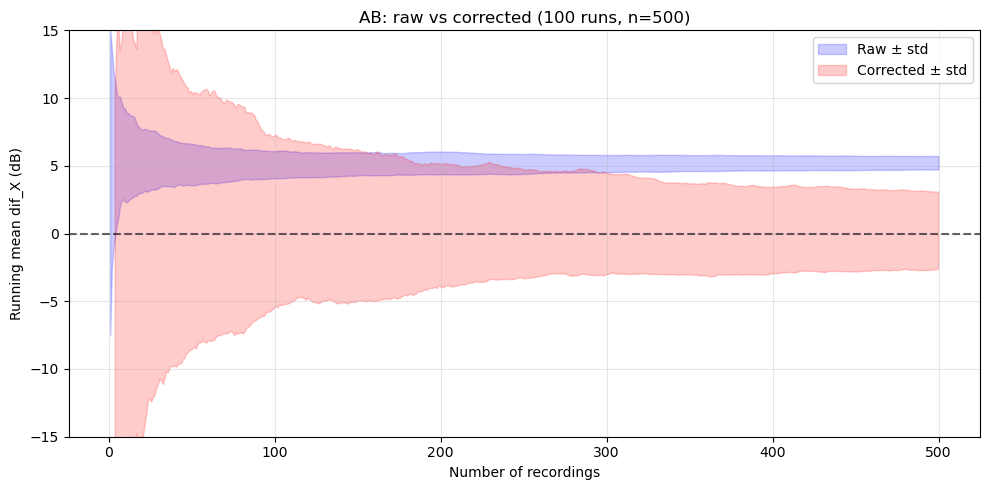

In [93]:
# ==============================
# Plot
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Raw
ax.fill_between(
    x,
    mean_AB - std_AB,
    mean_AB + std_AB,
    color="blue",
    alpha=0.20,
    label="Raw ± std"
)

# Regression Corrected
ax.fill_between(
    x,
    corr_mean_AB - corr_std_AB,
    corr_mean_AB + corr_std_AB,
    color="red",
    alpha=0.20,
    label="Corrected ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: raw vs corrected "
    f"({R} runs, n={max_steps})"
)

ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.ylim(-15, 15)

plt.tight_layout()
plt.show()

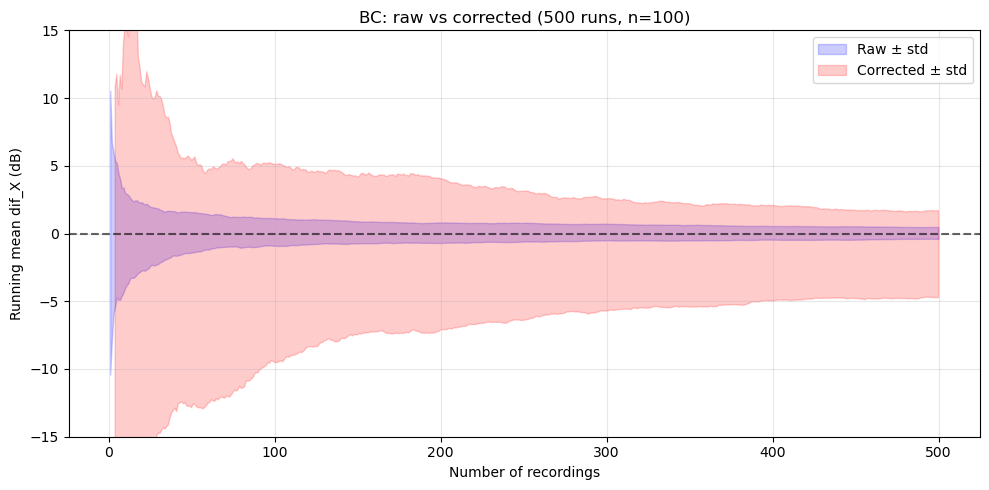

In [94]:
# ==============================
# Plot
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Raw
ax.fill_between(
    x,
    mean_BC - std_BC,
    mean_BC + std_BC,
    color="blue",
    alpha=0.20,
    label="Raw ± std"
)

# Regression Corrected
ax.fill_between(
    x,
    corr_mean_BC - corr_std_BC,
    corr_mean_BC + corr_std_BC,
    color="red",
    alpha=0.20,
    label="Corrected ± std"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: raw vs corrected "
    f"({R} runs, n={max_steps})"
)

ax.set_title("BC: raw vs corrected (500 runs, n=100)")
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Running mean dif_X (dB)")
ax.grid(alpha=0.3)
ax.legend()

plt.ylim(-15, 15)

plt.tight_layout()
plt.show()

##### 7) Simple Network Correction

In [98]:
# ==============================
# ABC Triangle
# 10 species
# ==============================

triangle_error_ABC_10 = (
    corr["AB"]
    + corr["BC"]
    - corr["AC"]
)

triangle_error_ABD_10 = (
    corr["AB"]
    + corr["BD"]
    - corr["AD"]
)

triangle_error_ABE_10 = (
    corr["AB"]
    + corr["BE"]
    - corr["AE"]
)

triangle_error_ABF_10 = (
    corr["AB"]
    + corr["BF"]
    - corr["AF"]
)

triangle_error_ABG_10 = (
    corr["AB"]
    + corr["BG"]
    - corr["AG"]
)

triangle_error_ABH_10 = (
    corr["AB"]
    + corr["BH"]
    - corr["AH"]
)

triangle_error_ABI_10 = (
    corr["AB"]
    + corr["BI"]
    - corr["AI"]
)

triangle_error_ABJ_10 = (
    corr["AB"]
    + corr["BJ"]
    - corr["AJ"]
)


# ==============================
# AB error
# 10 species
# ==============================

distributed_error_AB_10 = (
    triangle_error_ABC_10
    + triangle_error_ABD_10
    + triangle_error_ABE_10
    + triangle_error_ABF_10
    + triangle_error_ABG_10
    + triangle_error_ABH_10
    + triangle_error_ABI_10
    + triangle_error_ABJ_10
) / (3 * 8)


# ==============================
# AB: regression + network
# 10 species
# ==============================

corr_net_AB_10 = (
    corr_AB
    - distributed_error_AB_10
)

In [99]:

# ==============================
# BC triangles
# 10 species
# ==============================

# triangle_error_ABC_10 already calculated

triangle_error_BCD_10 = (
    corr["BC"]
    + corr["CD"]
    - corr["BD"]
)

triangle_error_BCE_10 = (
    corr["BC"]
    + corr["CE"]
    - corr["BE"]
)

triangle_error_BCF_10 = (
    corr["BC"]
    + corr["CF"]
    - corr["BF"]
)

triangle_error_BCG_10 = (
    corr["BC"]
    + corr["CG"]
    - corr["BG"]
)

triangle_error_BCH_10 = (
    corr["BC"]
    + corr["CH"]
    - corr["BH"]
)

triangle_error_BCI_10 = (
    corr["BC"]
    + corr["CI"]
    - corr["BI"]
)

triangle_error_BCJ_10 = (
    corr["BC"]
    + corr["CJ"]
    - corr["BJ"]
)


# ==============================
# BC error
# 10 species
# ==============================

distributed_error_BC_10 = (
    triangle_error_ABC_10
    + triangle_error_BCD_10
    + triangle_error_BCE_10
    + triangle_error_BCF_10
    + triangle_error_BCG_10
    + triangle_error_BCH_10
    + triangle_error_BCI_10
    + triangle_error_BCJ_10
) / (3 * 8)


# ==============================
# BC: regression + network
# 10 species
# ==============================

corr_net_BC_10 = (
    corr_BC
    - distributed_error_BC_10
)


In [100]:

# ==============================
# Metrics for 100 runs
# 10 species
# ==============================

corr_net_mean_AB_10 = np.nanmean(
    corr_net_AB_10,
    axis=0
)

corr_net_std_AB_10 = np.nanstd(
    corr_net_AB_10,
    axis=0
)


corr_net_mean_BC_10 = np.nanmean(
    corr_net_BC_10,
    axis=0
)

corr_net_std_BC_10 = np.nanstd(
    corr_net_BC_10,
    axis=0
)

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\2110839463.py:6: RuntimeWarning: Mean of empty slice
  corr_net_mean_AB_10 = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\2110839463.py:17: RuntimeWarning: Mean of empty slice
  corr_net_mean_BC_10 = np.nanmean(


##### 8) Final Corrected Plot

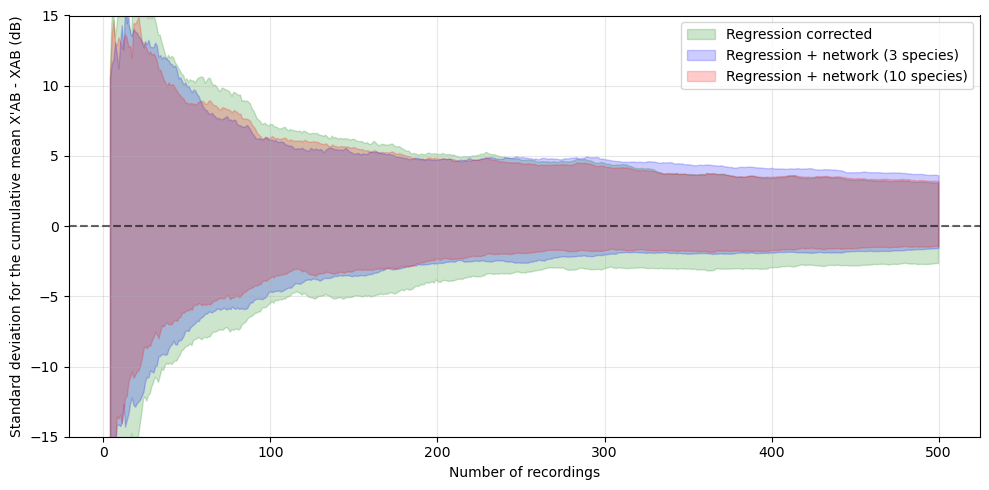

In [101]:
# ==============================
# Plot AB
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# # Raw
# ax.fill_between(
#     x,
#     mean_AB - std_AB,
#     mean_AB + std_AB,
#     color="blue",
#     alpha=0.20,
#     label="Raw ± std"
# )

# Regression corrected
ax.fill_between(
    x,
    corr_mean_AB - corr_std_AB,
    corr_mean_AB + corr_std_AB,
    color="green",
    alpha=0.20,
    label="Regression corrected"
)

# Regression corrected + 3-species Network
ax.fill_between(
    x,
    corr_net_mean_AB_3 - corr_net_std_AB_3,
    corr_net_mean_AB_3 + corr_net_std_AB_3,
    color="blue",
    alpha=0.20,
    label="Regression + network (3 species)"
)

# Regression corrected + 10-species Network
ax.fill_between(
    x,
    corr_net_mean_AB_10 - corr_net_std_AB_10,
    corr_net_mean_AB_10 + corr_net_std_AB_10,
    color="red",
    alpha=0.20,
    label="Regression + network (10 species)"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"AB: 2 phase correction "
    f"({R} runs, n={max_steps}, 10 species)"
)

# ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Standard deviation for the cumulative mean X'AB - XAB (dB)")
ax.set_ylim(-15, 15)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

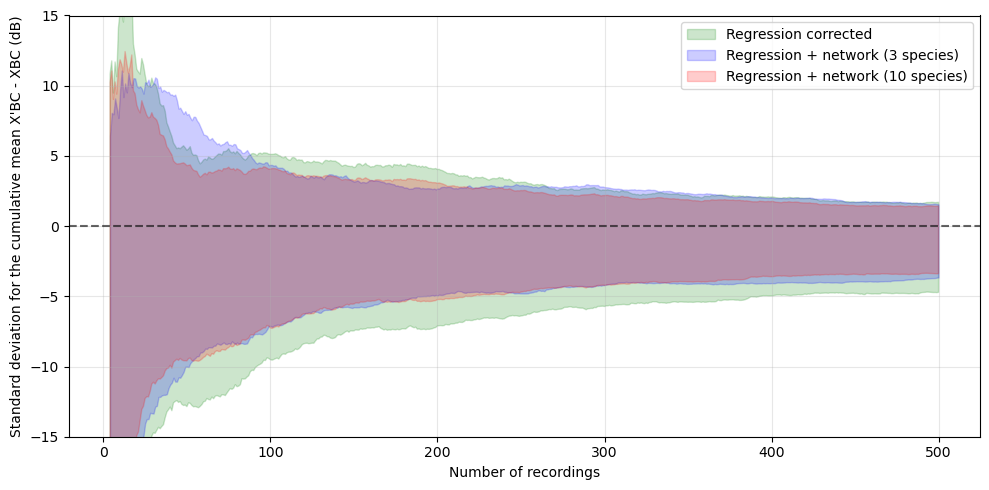

In [102]:
# ==============================
# Plot BC
# ==============================

x = np.arange(1, max_steps + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# # Raw
# ax.fill_between(
#     x,
#     mean_BC - std_BC,
#     mean_BC + std_BC,
#     color="blue",
#     alpha=0.20,
#     label="Raw ± std"
# )

# # Regression corrected
ax.fill_between(
    x,
    corr_mean_BC - corr_std_BC,
    corr_mean_BC + corr_std_BC,
    color="green",
    alpha=0.20,
    label="Regression corrected"
)

# Regression corrected + 3-species Network
ax.fill_between(
    x,
    corr_net_mean_BC_3 - corr_net_std_BC_3,
    corr_net_mean_BC_3 + corr_net_std_BC_3,
    color="blue",
    alpha=0.20,
    label="Regression + network (3 species)"
)

# Regression corrected + 10-species Network
ax.fill_between(
    x,
    corr_net_mean_BC_10 - corr_net_std_BC_10,
    corr_net_mean_BC_10 + corr_net_std_BC_10,
    color="red",
    alpha=0.20,
    label="Regression + network (10 species)"
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
    alpha=0.6
)

title = (
    f"BC: 2 phase correction "
    f"({R} runs, n={max_steps}, 10 species)"
)

# ax.set_title(title)
ax.set_xlabel("Number of recordings")
ax.set_ylabel("Standard deviation for the cumulative mean X'BC - XBC (dB)")
ax.set_ylim(-15, 15)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

#### Evaluation 3-species network vs. 10-species network

In [108]:
# ==============================
# Comparison 3 vs 10
# ==============================

x = np.arange(1, max_steps + 1)


# ==============================
# AB
# ==============================

rmse_AB_3 = np.sqrt(
    np.nanmean(
        corr_net_AB_3**2,
        axis=0
    )
)

rmse_AB_10 = np.sqrt(
    np.nanmean(
        corr_net_AB_10**2,
        axis=0
    )
)

mae_AB_3 = np.nanmean(
    np.abs(corr_net_AB_3),
    axis=0
)

mae_AB_10 = np.nanmean(
    np.abs(corr_net_AB_10),
    axis=0
)


# ==============================
# BC
# ==============================

rmse_BC_3 = np.sqrt(
    np.nanmean(
        corr_net_BC_3**2,
        axis=0
    )
)

rmse_BC_10 = np.sqrt(
    np.nanmean(
        corr_net_BC_10**2,
        axis=0
    )
)

mae_BC_3 = np.nanmean(
    np.abs(corr_net_BC_3),
    axis=0
)

mae_BC_10 = np.nanmean(
    np.abs(corr_net_BC_10),
    axis=0
)

C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:13: RuntimeWarning: Mean of empty slice
  np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:20: RuntimeWarning: Mean of empty slice
  np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:26: RuntimeWarning: Mean of empty slice
  mae_AB_3 = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:31: RuntimeWarning: Mean of empty slice
  mae_AB_10 = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:42: RuntimeWarning: Mean of empty slice
  np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:49: RuntimeWarning: Mean of empty slice
  np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:55: RuntimeWarning: Mean of empty slice
  mae_BC_3 = np.nanmean(
C:\Users\vasco\AppData\Local\Temp\ipykernel_8724\4126073225.py:60: RuntimeWarning: Mean of empty slice
  mae_BC_10 = np.nanmean(


In [109]:
# ==============================
# Final Results
# ==============================

print("\n" + "=" * 60)
print("AB")

print(
    f"3 species network:  "
    f"RMSE = {rmse_AB_3[-1]:.4f} dB  "
    f"MAE = {mae_AB_3[-1]:.4f} dB"
)

print(
    f"10 species network: "
    f"RMSE = {rmse_AB_10[-1]:.4f} dB  "
    f"MAE = {mae_AB_10[-1]:.4f} dB"
)


print("\n" + "=" * 60)
print("BC")

print(
    f"3 species network:  "
    f"RMSE = {rmse_BC_3[-1]:.4f} dB  "
    f"MAE = {mae_BC_3[-1]:.4f} dB"
)

print(
    f"10 species network: "
    f"RMSE = {rmse_BC_10[-1]:.4f} dB  "
    f"MAE = {mae_BC_10[-1]:.4f} dB"
)


AB
3 species network:  RMSE = 2.7847 dB  MAE = 2.2508 dB
10 species network: RMSE = 2.4772 dB  MAE = 1.9173 dB

BC
3 species network:  RMSE = 2.8053 dB  MAE = 2.2437 dB
10 species network: RMSE = 2.5978 dB  MAE = 2.1300 dB


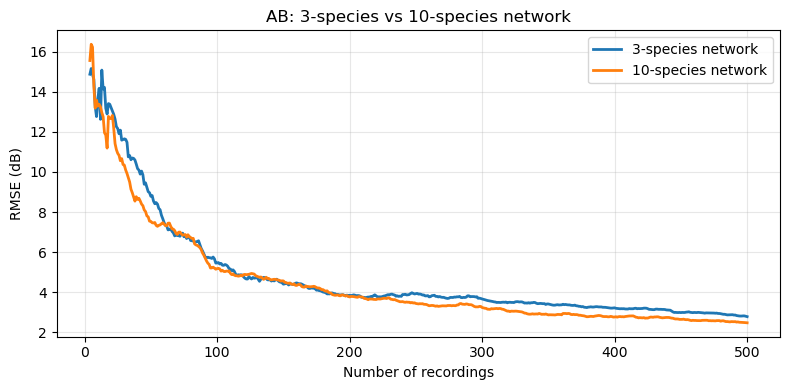

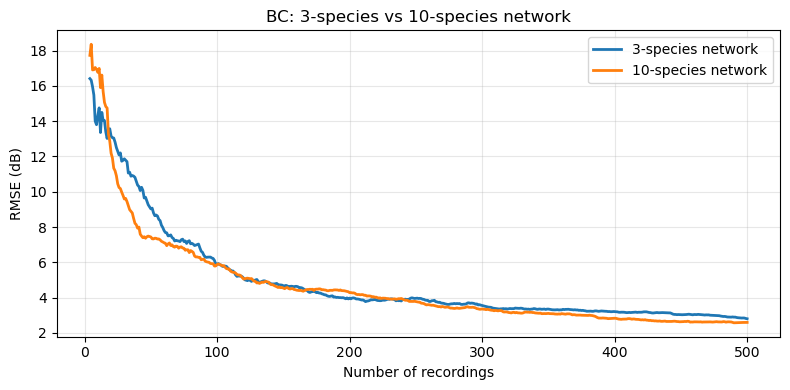

In [110]:
# ==============================
# Plot RMSE - AB
# ==============================

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    x,
    rmse_AB_3,
    linewidth=2,
    label="3-species network"
)

ax.plot(
    x,
    rmse_AB_10,
    linewidth=2,
    label="10-species network"
)

ax.set_xlabel("Number of recordings")
ax.set_ylabel("RMSE (dB)")
ax.set_title("AB: 3-species vs 10-species network")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# ==============================
# Plot RMSE - BC
# ==============================

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    x,
    rmse_BC_3,
    linewidth=2,
    label="3-species network"
)

ax.plot(
    x,
    rmse_BC_10,
    linewidth=2,
    label="10-species network"
)

ax.set_xlabel("Number of recordings")
ax.set_ylabel("RMSE (dB)")
ax.set_title("BC: 3-species vs 10-species network")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

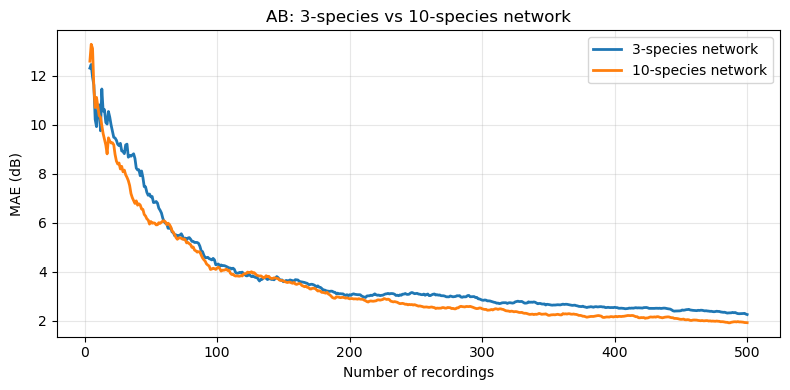

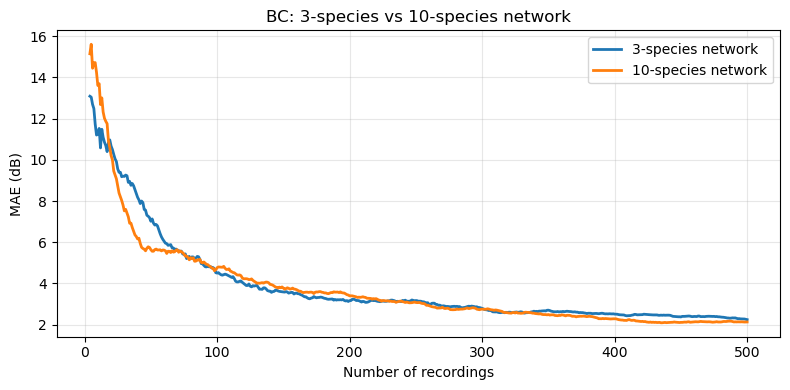

In [111]:
# ==============================
# Plot MAE - AB
# ==============================

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    x,
    mae_AB_3,
    linewidth=2,
    label="3-species network"
)

ax.plot(
    x,
    mae_AB_10,
    linewidth=2,
    label="10-species network"
)

ax.set_xlabel("Number of recordings")
ax.set_ylabel("MAE (dB)")
ax.set_title("AB: 3-species vs 10-species network")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# ==============================
# Plot MAE - BC
# ==============================

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    x,
    mae_BC_3,
    linewidth=2,
    label="3-species network"
)

ax.plot(
    x,
    mae_BC_10,
    linewidth=2,
    label="10-species network"
)

ax.set_xlabel("Number of recordings")
ax.set_ylabel("MAE (dB)")
ax.set_title("BC: 3-species vs 10-species network")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [113]:
import pandas as pd
import numpy as np


comparison_rows = []


# ==============================
# AB
# ==============================

AB_methods = {
    "Original": running_mean["AB"],
    "Regression": corr_AB,
    "Regression + Network": corr_net_AB_10
}

for method, data in AB_methods.items():

    final_values = data[:, -1]

    mean_value = np.nanmean(final_values)
    std_value = np.nanstd(final_values)

    rmse_value = np.sqrt(
        np.nanmean(final_values**2)
    )

    mae_value = np.nanmean(
        np.abs(final_values)
    )

    comparison_rows.append({
        "Pair": "AB",
        "Method": method,
        "Mean (dB)": mean_value,
        "STD (dB)": std_value,
        "RMSE (dB)": rmse_value,
        "MAE (dB)": mae_value
    })


# ==============================
# BC
# ==============================

BC_methods = {
    "Original": running_mean["BC"],
    "Regression": corr_BC,
    "Regression + Network": corr_net_BC_10
}

for method, data in BC_methods.items():

    final_values = data[:, -1]

    mean_value = np.nanmean(final_values)
    std_value = np.nanstd(final_values)

    rmse_value = np.sqrt(
        np.nanmean(final_values**2)
    )

    mae_value = np.nanmean(
        np.abs(final_values)
    )

    comparison_rows.append({
        "Pair": "BC",
        "Method": method,
        "Mean (dB)": mean_value,
        "STD (dB)": std_value,
        "RMSE (dB)": rmse_value,
        "MAE (dB)": mae_value
    })


# ==============================
# Table
# ==============================

comparison_table = pd.DataFrame(
    comparison_rows
)

comparison_table = comparison_table.round(3)

print(comparison_table)

  Pair                Method  Mean (dB)  STD (dB)  RMSE (dB)  MAE (dB)
0   AB              Original      5.222     0.500      5.246     5.222
1   AB            Regression      0.195     2.860      2.867     2.247
2   AB  Regression + Network      0.907     2.305      2.477     1.917
3   BC              Original      0.042     0.441      0.443     0.370
4   BC            Regression     -1.510     3.202      3.541     2.831
5   BC  Regression + Network     -0.980     2.406      2.598     2.130
